## Quadro completo del Notebook 3

- **Sezione 1 — Setup e Caricamento Dati**
- **Sezione 2 — Algoritmi Core (Dai 2D al Catalogo 3D)**
- **Sezione 3 — Calibrazione della massa e diagnosi del bias**
    - 3.1 Stima della massa e fit log-log
    - 3.2 L'errore relativo di massa in funzione della massa vera
    - 3.3 Perché la completezza non è al $100\%$? (Decomposizione Seen/Not Seen)
- **Sezione 4 — Diagnosi dei Falsi Positivi e Transizione delle Soglie** *(UNIFICATA)*
    - 4.1 La fotografia statica: Matching, Classificazione FP e Purity Fisica
    - 4.2 La transizione dinamica: Origine dei nuovi oggetti da $0.99$ a $0.95$
    - 4.3 Ispezione Visiva degli Oggetti di Rumore
    - 4.4 Conclusione: un catalogo arricchito, non inquinato
- **Sezione 5 — Esplorazione della Griglia $4\times3$ e Trade-off**
    - 5.1 Esecuzione della griglia e tabelle
    - 5.2 Analisi visiva dei trade-off ($C$, $P$, $n_{\mathrm{pred}}$)
    - 5.3 Scelta della configurazione operativa $(0.95,\, 4)$
    - 5.4 Confronto Visivo delle Soglie $(0.85,\, 0.90,\, 0.95,\, 0.99)$ 
- **Sezione 6 — Funzione di Massa (HMF) e Completezza**
    - 6.1 HMF e Completezza per bin di massa
    - 6.2 Completezza e Purity per Aloni Ben Risolti ($M_{\mathrm{thr}}$)
- **Sezione 7 — Robustness Check: il Background Proiettato**
    - 7.1 Stima del background e ricalcolo masse
    - 7.2 Confronto massa prima vs dopo
- **Sezione 8 — Riepilogo Finale**
    - 8.1 Tabella riassuntiva

## 1. Setup e Caricamento Dati

L'obiettivo è trasformare le mappe di probabilità generate dalla U-Net nel Notebook 2 in un **catalogo fisico 3D** di aloni, caratterizzato da coordinate spaziali $(x, y, z)$ e massa stimata $M$.

**Ricostruzione della densità:**
Partiamo dalle patch normalizzate $X$ e ricostruiamo la densità SPH grezza $\rho$ invertendo lo z-score robusto applicato nel Notebook 1:

$$
\rho(x, y) = 10^{\,X(x, y)\cdot \sigma + \mu}
$$

**Stima del raggio:**
Per il matching geometrico useremo il raggio stimato

$$
R_{200}^{\mathrm{est}} = \left(\frac{3M}{4\pi \cdot 200\,\rho_c}\right)^{1/3}
$$

Si tratta di un'**approssimazione sferica** usata per definire la tolleranza spaziale durante l'accoppiamento (matching), non per la fisica dell'alone.

In [26]:
# ============================================================
# 1 — SETUP, LIBRERIE E CARICAMENTO DATI
# ============================================================
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import h5py
import hdf5plugin
import seaborn as sns

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---------------- percorsi ----------------
DATA_DIR = r"C:\Users\kekko\Downloads\Python\TESI\CAMELS_data"
RUN_DIR  = os.path.join(DATA_DIR, "unet")
IN_ROOT  = os.path.join(DATA_DIR, "input_data")

RUN_NAME = "LH_105"
SNAP_TAG = "090"
ROLE     = "val"

# ---------------- configurazione ----------------
N_SLICES, IMG_SIZE, PATCH_SIZE = 25, 1024, 256
EMPTY_FILL = -3.0
RHO_CRIT0  = 2.7754e11

# Soglie e aree da testare (il cuore del notebook 3)
SOGLIE_CANDIDATE = [0.85, 0.90, 0.95, 0.99]
AREE_CANDIDATE   = [4, 6, 12]

# Algoritmo
MIN_AREA_2D_PX   = 1        # Filtro di sicurezza (tiene tutto)
LINK_FLOOR_PX    = 3        # Floor linking [px]
MIN_TOL_PX       = 3        # Floor matching [px]
LINK_NEIGHBORS   = 2        # Collega s->s+1 e s->s+2

# ---------------- caricamento ----------------
SIM_DIR   = os.path.join(IN_ROOT, f"sim_{RUN_NAME}_{SNAP_TAG}")
PROB_FILE = os.path.join(RUN_DIR, "val_prob_slices.npy")
CAT_PATH  = os.path.join(DATA_DIR, "Simulations", RUN_NAME, f"groups_{RUN_NAME}", f"groups_{SNAP_TAG}_{RUN_NAME}.hdf5")

def tiles_to_slices(tiles, patch, img):
    """Ricostruisce fette 1024². Ordine: indice = slice*16 + gy*4 + gx."""
    n_grid = img // patch
    n = tiles.shape[0] // n_grid ** 2
    out = np.empty((n, img, img), dtype=tiles.dtype)
    for i in range(n):
        for k in range(n_grid ** 2):
            gy, gx = divmod(k, n_grid)
            out[i, gy*patch:(gy+1)*patch, gx*patch:(gx+1)*patch] = tiles[i*n_grid**2 + k]
    return out

# Metadati
with open(os.path.join(SIM_DIR, "dataset_info.json")) as fh:
    info = json.load(fh)
LBOX     = float(info["LBOX_MPC_H"])
MASS_CUT = float(info["MASS_CUT_MSUNH"])
SIG_D    = float(info["SIG_D"])
MED_D    = float(info["MED_D"])

# Ricostruzione densità (con FIX float32)
Xn = tiles_to_slices(
        np.asarray(np.load(os.path.join(SIM_DIR, "X_patches.npy"), mmap_mode="r")[:, 0], dtype=np.float32),
        PATCH_SIZE, IMG_SIZE)
# Fix: usiamo <= -2.9 per evitare che errori float32 bypassino l'uguaglianza esatta
raw = np.where(Xn <= -2.9, 0.0, 10.0 ** (Xn * SIG_D + MED_D)).astype(np.float32)
del Xn

# Probabilità U-Net e mpu
probs = np.load(PROB_FILE).astype(np.float32)
mpu   = np.load(os.path.join(SIM_DIR, "mpu_per_slice.npy"))

# Cataloghi (Group + Subhalo)
with h5py.File(CAT_PATH, "r") as f:
    g  = f["Group"]
    sh = f["Subhalo"]
    fof_full = {
        "pos":  g["GroupPos"][:].astype(np.float64) / 1000.0,
        "r200": g["Group_R_Crit200"][:].astype(np.float64) / 1000.0,
        "mass": g["GroupMass"][:].astype(np.float64) * 1e10,
    }
    sub_full = {
        "pos":  sh["SubhaloPos"][:].astype(np.float64) / 1000.0,
        "mass": sh["SubhaloMass"][:].astype(np.float64) * 1e10,
        "r200": np.maximum(2.0 * sh["SubhaloHalfmassRad"][:].astype(np.float64) / 1000.0, 3.0 * (LBOX / IMG_SIZE)),
    }

# Pulizia cataloghi
keep = np.isfinite(fof_full["pos"]).all(1) & (fof_full["r200"] > 0)
for k in fof_full: fof_full[k] = fof_full[k][keep]
keep = np.isfinite(sub_full["pos"]).all(1) & (sub_full["mass"] > 0)
for k in sub_full: sub_full[k] = sub_full[k][keep]

# Catalogo tagliato (target di training)
sel = fof_full["mass"] >= MASS_CUT
fof = {k: v[sel] for k, v in fof_full.items()}

# Geometria derivata
NS     = raw.shape[0]
IMG    = raw.shape[1]
PX_MPC = LBOX / IMG
DZ     = LBOX / NS
MIN_TOL_MPC    = MIN_TOL_PX * PX_MPC
LINK_FLOOR_MPC = LINK_FLOOR_PX * PX_MPC
STRUCT8        = np.ones((3, 3), bool)

print(f"Simulazione {RUN_NAME}_{SNAP_TAG}: LBOX={LBOX:.1f} Mpc/h | DZ={DZ:.2f} Mpc/h | PX={PX_MPC:.4f} Mpc/h")
print(f"  mappe : raw {raw.shape} | probs {probs.shape}")
print(f"  Group : {len(fof_full['mass']):,} totali → {len(fof['mass']):,} sopra MASS_CUT={MASS_CUT:.2e}")
print(f"  Subhalo: {len(sub_full['mass']):,}")

Simulazione LH_105_090: LBOX=25.0 Mpc/h | DZ=1.00 Mpc/h | PX=0.0244 Mpc/h
  mappe : raw (25, 1024, 1024) | probs (25, 1024, 1024)
  Group : 12,304 totali → 4,701 sopra MASS_CUT=9.63e+09
  Subhalo: 16,223


## 2. Algoritmi della Pipeline

Per passare da una mappa 2D di probabilità a un catalogo 3D, seguiamo tre passaggi logici:

1. **Estrazione Blob 2D** (`extract_blobs`): binarizziamo la mappa a una certa soglia $t$. Per gestire la periodicità lungo i bordi $(x, y)$, eseguiamo il labeling su un mosaico $3\times 3$ della fetta, estraendo poi le statistiche solo dal riquadro centrale. 
Per ogni blob si calcolano:
    - **centroide circolare** $(x,y)$ — media di $\sin(2\pi x/L)$ e $\cos(2\pi x/L)$, robusta al wrap periodico;
    - **massa** $m_{\rm blob} = (\sum_p \rho_p) \cdot \mathrm{mpu}_{\rm slice}$, dove `mpu` è la massa per unità ricavata in notebook 01 dalla conservazione della massa totale;
    - **raggio equivalente** $r_{\rm eq} = \sqrt{A/\pi}$;
    - **probabilità di picco** e indice di fetta.

2. **Linking 3D** (`link_blobs`): colleghiamo i blob che appartengono a fette adiacenti. Se due blob sono in fette vicine ($s \to s+1$ o $s \to s+2$) e la loro distanza proiettata in $XY$ è inferiore alla somma dei loro raggi (con un floor di $3\,\mathrm{px}$ per evitare frammentazioni spurie), li consideriamo parte dello stesso oggetto 3D.

3. **Costruzione Catalogo** (`build_catalog`): raggruppiamo i blob connessi in un unico oggetto. La massa è la somma delle masse dei blob. Le coordinate $(x, y, z)$ sono calcolate come media circolare pesata per la massa, così da essere precise anche se l'oggetto attraversa il bordo del box.

**Matching** (`match_catalogs`):
Accoppiamo i nostri oggetti predetti con quelli veri (FoF) usando un matching greedy $1$-a-$1$. Due oggetti matchano se la loro distanza proiettata in $XY$ è minore di $\max\!\left(R_{200},\, 3\,\mathrm{px}\right)$ e se si trovano nella stessa fetta in $Z$ ($\left|\Delta z\right| \le dz$).

**Diagnosi dei Falsi Positivi** (`classify_fps`):
Le predizioni che non matchano nessun FoF sopra `MASS_CUT` non sono necessariamente errori. Le classifichiamo in 4 categorie:

- **Sotto cut**: matchano un FoF reale ma con massa inferiore al limite di training (la rete li vede, il catalogo no).
- **Doppia**: matchano un FoF già trovato, ma lo frammentano in due pezzi.
- **Subhalo**: matchano una sottostruttura reale (Subfind), non visibile nel catalogo Group principale.
- **Rumore**: nessun corrispettivo fisico (i veri falsi positivi).

In [2]:
# ============================================================
# 2 — FUNZIONI CORE DELLA PIPELINE (ottimizzate)
# ============================================================
from scipy.ndimage import label as nd_label
from scipy.spatial import cKDTree

# ---- cache blob per soglia (evita ricalcoli identici nella griglia) ----
_BLOB_CACHE = {}

def get_blobs(t):
    k = round(float(t), 4)
    if k not in _BLOB_CACHE:
        _BLOB_CACHE[k] = extract_blobs(probs, raw, mpu, LBOX, t=k, min_area=MIN_AREA_2D_PX)
    return _BLOB_CACHE[k]

def get_linked(t):
    k = ("linked", round(float(t), 4))
    if k not in _BLOB_CACHE:
        _BLOB_CACHE[k] = link_blobs(get_blobs(t), LBOX, n_neighbors=LINK_NEIGHBORS)
    return _BLOB_CACHE[k]

# ---- distanza periodica (invariata, usata da link_blobs) ----
def pdist_periodic(a, b, lbox):
    dx = (a[:, None, 0] - b[None, :, 0] + lbox/2) % lbox - lbox/2
    dy = (a[:, None, 1] - b[None, :, 1] + lbox/2) % lbox - lbox/2
    return np.hypot(dx, dy)

def extract_blobs(probs, raw, mpu, lbox, t, min_area=1):
    """Estrae blob 2D a soglia t. Labeling su mosaico 3x3 per periodicità XY completa (8-conn)."""
    B = {k: [] for k in ("x", "y", "mass", "area", "r_eq", "prob", "slice")}
    for s in range(NS):
        lab_big, _ = nd_label(np.tile(probs[s] > t, (3, 3)), STRUCT8)
        core = lab_big[IMG:2*IMG, IMG:2*IMG]
        ys, xs = np.nonzero(core)
        if len(ys) == 0:
            continue
        lb = core[ys, xs]
        uniq, cid = np.unique(lb, return_inverse=True)
        k = len(uniq)

        area = np.bincount(cid, minlength=k).astype(np.float64)
        mass = np.bincount(cid, weights=raw[s][ys, xs].astype(np.float64),
                           minlength=k) * float(mpu[s])
        ax_ = 2 * np.pi * (xs + 0.5) / IMG
        ay_ = 2 * np.pi * (ys + 0.5) / IMG
        xc = (np.arctan2(np.bincount(cid, np.sin(ax_), minlength=k),
                         np.bincount(cid, np.cos(ax_), minlength=k)) / (2*np.pi)) % 1.0 * lbox
        yc = (np.arctan2(np.bincount(cid, np.sin(ay_), minlength=k),
                         np.bincount(cid, np.cos(ay_), minlength=k)) / (2*np.pi)) % 1.0 * lbox
        r_eq = np.sqrt(area / np.pi) * PX_MPC

        # peak via np.maximum.reduceat (più rapido di ndimage.maximum, stesso risultato)
        order = np.argsort(cid, kind="stable")
        starts = np.searchsorted(cid[order], np.arange(k))
        peak = np.maximum.reduceat(probs[s][ys[order], xs[order]], starts)

        good = area >= min_area
        B["x"] += xc[good].tolist();   B["y"] += yc[good].tolist()
        B["mass"] += mass[good].tolist(); B["area"] += area[good].tolist()
        B["r_eq"] += r_eq[good].tolist(); B["prob"] += peak[good].tolist()
        B["slice"] += [s] * int(good.sum())
    return {k: np.asarray(v) for k, v in B.items()}

# ---- link_blobs (invariata) ----
def link_blobs(B, lbox, n_neighbors=LINK_NEIGHBORS):
    n = len(B["x"])
    edges = []
    for k in range(1, n_neighbors + 1):
        scale = 1.0 if k == 1 else 0.7
        for s in range(NS):
            s2 = (s + k) % NS
            ia = np.flatnonzero(B["slice"] == s)
            ib = np.flatnonzero(B["slice"] == s2)
            if len(ia) == 0 or len(ib) == 0:
                continue
            d = pdist_periodic(np.c_[B["x"][ia], B["y"][ia]],
                               np.c_[B["x"][ib], B["y"][ib]], lbox)
            link_len = scale * np.maximum(
                np.maximum(B["r_eq"][ia][:, None], B["r_eq"][ib][None, :]), LINK_FLOOR_MPC)
            ii, jj = np.nonzero(d <= link_len)
            edges.append(np.c_[ia[ii], ib[jj]])
    edges = np.concatenate(edges) if edges else np.zeros((0, 2), int)
    graph = coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(n, n))
    _, comp = connected_components(graph, directed=False)
    return comp

# ---- build_catalog: vettorizzato con bincount (no loop Python) ----
def build_catalog(B, comp, lbox, dz, min_area_3d):
    z_c = (np.arange(NS) + 0.5) * dz
    m, a = B["mass"], B["area"]
    uniq, cid = np.unique(comp, return_inverse=True)
    n = len(uniq)
    M = np.bincount(cid, weights=m, minlength=n)
    A = np.bincount(cid, weights=a, minlength=n)
    th  = 2 * np.pi * z_c[B["slice"]] / lbox
    thx = 2 * np.pi * B["x"] / lbox
    thy = 2 * np.pi * B["y"] / lbox
    z = (np.arctan2(np.bincount(cid, m*np.sin(th),  minlength=n),
                    np.bincount(cid, m*np.cos(th),  minlength=n)) / (2*np.pi)) % 1.0 * lbox
    x = (np.arctan2(np.bincount(cid, m*np.sin(thx), minlength=n),
                    np.bincount(cid, m*np.cos(thx), minlength=n)) / (2*np.pi)) % 1.0 * lbox
    y = (np.arctan2(np.bincount(cid, m*np.sin(thy), minlength=n),
                    np.bincount(cid, m*np.cos(thy), minlength=n)) / (2*np.pi)) % 1.0 * lbox
    r_est = (3 * M / (4 * np.pi * 200 * RHO_CRIT0)) ** (1/3)
    keep = A >= min_area_3d
    return {"x": x[keep], "y": y[keep], "z": z[keep],
            "mass": M[keep], "r200_est": r_est[keep], "area_tot": A[keep]}

# ---- match_catalogs: cKDTree periodico ----
def match_catalogs(pred, ref, lbox, dz, tol_scale=1.0):
    n_pred, n_ref = len(pred["mass"]), len(ref["mass"])
    if n_pred == 0 or n_ref == 0:
        return np.zeros((0, 2), int), np.zeros(n_pred, bool), np.zeros(n_ref, bool)
    r_match = np.maximum(ref["r200"], MIN_TOL_MPC) * tol_scale
    rmax = float(r_match.max()) * 1.01
    tree = cKDTree(ref["pos"][:, :2], boxsize=lbox)
    xy_pred = np.column_stack([pred["x"], pred["y"]])
    z_pred  = pred["z"]
    rxy, rz = ref["pos"][:, :2], ref["pos"][:, 2]

    ci, cj, cd = [], [], []
    for i, js in enumerate(tree.query_ball_point(xy_pred, r=rmax)):
        if not js:
            continue
        js = np.asarray(js, dtype=int)
        dx = (xy_pred[i, 0] - rxy[js, 0] + lbox/2) % lbox - lbox/2
        dy = (xy_pred[i, 1] - rxy[js, 1] + lbox/2) % lbox - lbox/2
        dxy = np.hypot(dx, dy)
        ok = dxy <= r_match[js]
        if not ok.any():
            continue
        dzp = (z_pred[i] - rz[js] + lbox/2) % lbox - lbox/2
        ok = ok & (np.abs(dzp) <= dz)
        if not ok.any():
            continue
        js_ok = js[ok]
        ci += [i] * len(js_ok); cj += js_ok.tolist(); cd += dxy[ok].tolist()

    if not ci:
        return np.zeros((0, 2), int), np.zeros(n_pred, bool), np.zeros(n_ref, bool)

    ci, cj, cd = np.asarray(ci, int), np.asarray(cj, int), np.asarray(cd)
    order = np.lexsort((cj, ci, cd))
    pm, fm = np.zeros(n_pred, bool), np.zeros(n_ref, bool)
    pairs = []
    for k in order:
        i, j = ci[k], cj[k]
        if not (pm[i] or fm[j]):
            pairs.append((i, j)); pm[i] = fm[j] = True
    return np.asarray(pairs, int).reshape(-1, 2), pm, fm

# ---- classify_fps (invariata, beneficia del nuovo match_catalogs) ----
def classify_fps(pred, pm, fof_full, sub_full, lbox, dz):
    fp_idx = np.flatnonzero(~pm)
    if len(fp_idx) == 0:
        return {"n_below": 0, "n_double": 0, "n_sub": 0, "n_noise": 0, "P_phys": 1.0}
    pred_fp = {k: pred[k][fp_idx] for k in pred}
    pairs_g, pm_g, _ = match_catalogs(pred_fp, fof_full, lbox, dz)
    _,       pm_s, _ = match_catalogs(pred_fp, sub_full, lbox, dz)
    mass_g = np.full(len(fp_idx), np.nan)
    for i, j in pairs_g:
        mass_g[i] = fof_full["mass"][j]
    cat = np.full(len(fp_idx), "", dtype=object)
    cat[pm_g & (mass_g <  MASS_CUT)] = "sotto cut"
    cat[pm_g & (mass_g >= MASS_CUT)] = "doppia"
    cat[(~pm_g) & pm_s]              = "subhalo"
    cat[(~pm_g) & (~pm_s)]           = "rumore"
    n_below  = int((cat == "sotto cut").sum())
    n_double = int((cat == "doppia").sum())
    n_sub    = int((cat == "subhalo").sum())
    n_noise  = int((cat == "rumore").sum())
    P_phys   = (pm.sum() + n_below + n_sub) / len(pred["mass"])
    return {"n_below": n_below, "n_double": n_double, "n_sub": n_sub,
            "n_noise": n_noise, "P_phys": float(P_phys)}

## 3. Calibrazione della massa e diagnosi del bias

Prima di lanciare una griglia di 12 configurazioni, testiamo una singola configurazione di riferimento (Baseline, $t = 0.95$, $\mathrm{area} = 4$) per verificare che la fisica della pipeline funzioni e per capire come la U-Net stima la massa.

#### 3.1 Stima della massa e fit log-log

La massa di un oggetto predetto è la somma della densità $\rho$ dei pixel che compongono i suoi blob 3D, moltiplicata per il fattore di calibrazione `mpu` (massa per unità) della fetta:

$$
M_{\mathrm{pred}} = \left(\sum_{\mathrm{blob}} \rho\right) \cdot \mathrm{mpu}_{\mathrm{slice}}
$$

Confrontiamo questa massa con quella del catalogo di verità (FoF) tramite un fit log-log:

$$
\log_{10} M_{\mathrm{FoF}} = a \cdot \log_{10} M_{\mathrm{pred}} + b
$$

La pendenza $a$ misura la compressione (se $a < 1$: alte masse sottostimate, basse sovrastimate).

#### 3.2 L'errore relativo di massa in funzione della massa vera

Per quantificare l'accuratezza della stima di massa, calcoliamo l'errore relativo:

$$
\frac{\Delta M}{M_{\mathrm{true}}} = \frac{M_{\mathrm{pred}} - M_{\mathrm{true}}}{M_{\mathrm{true}}}
$$

Suddividiamo gli aloni in bin di massa $M_{\mathrm{true}}$ (FoF) e per ciascun bin calcoliamo la **mediana** (linea centrale, ci dice se c'è bias) e lo **scatter $1\sigma$** definito come $\frac{P_{84} - P_{16}}{2}$ (barre d'errore, ci dice l'incertezza). Un fit ideale avrebbe mediana a $0$ e barre d'errore che si restringono per gli aloni massicci.

In [3]:
# ============================================================
# 3.2 — PIPELINE, FIT DI MASSA E BASELINE (Confronto Con/Senza MASS_CUT)
# ============================================================
def mass_stats(pairs, pred, fof):
    lp = np.log10(pred["mass"][pairs[:, 0]])
    lt = np.log10(fof["mass"][pairs[:, 1]])
    a, b = np.polyfit(lp, lt, 1)
    res  = lt - (a * lp + b)
    dlog = lt - lp
    sig_mad = 1.4826 * np.median(np.abs(res - np.median(res)))
    return {"lp": lp, "lt": lt, "dlog": dlog, "a": float(a), "b": float(b),
            "sigma_mad": float(sig_mad), "median_dlog": float(np.median(dlog))}

def run_pipeline(t_val, area3d):
    """Pipeline completa con cache su (t)."""
    B    = get_blobs(t_val)
    comp = get_linked(t_val)
    pred = build_catalog(B, comp, LBOX, DZ, min_area_3d=area3d)
    if len(pred["mass"]) == 0:
        return None
    pairs, pm, fm = match_catalogs(pred, fof, LBOX, DZ)
    fp_res = classify_fps(pred, pm, fof_full, sub_full, LBOX, DZ)
    n_pred = len(pred["mass"])
    return {
        "t": float(t_val), "area": int(area3d),
        "n_pred": int(n_pred), "n_match": int(len(pairs)),
        "C": float(fm.sum() / len(fof["mass"])),
        "P_raw": float(pm.sum() / n_pred),
        "P_phys": fp_res["P_phys"],
        "n_below": fp_res["n_below"], "n_double": fp_res["n_double"],
        "n_sub": fp_res["n_sub"], "n_noise": fp_res["n_noise"],
        "pred": pred, "pairs": pairs, "pm": pm, "fm": fm,
    }

Baseline (t=0.95, area=4):
  n_pred = 5,962 | Match = 3,846
  C      = 0.818 | P_phys = 0.9968
  Fit massa (n=3,846): a=0.884, sigma_MAD=0.133 dex

Senza MASS_CUT (Group completo):
  Match = 5,930
  Fit massa (n=5,930): a=0.862, sigma_MAD=0.182 dex


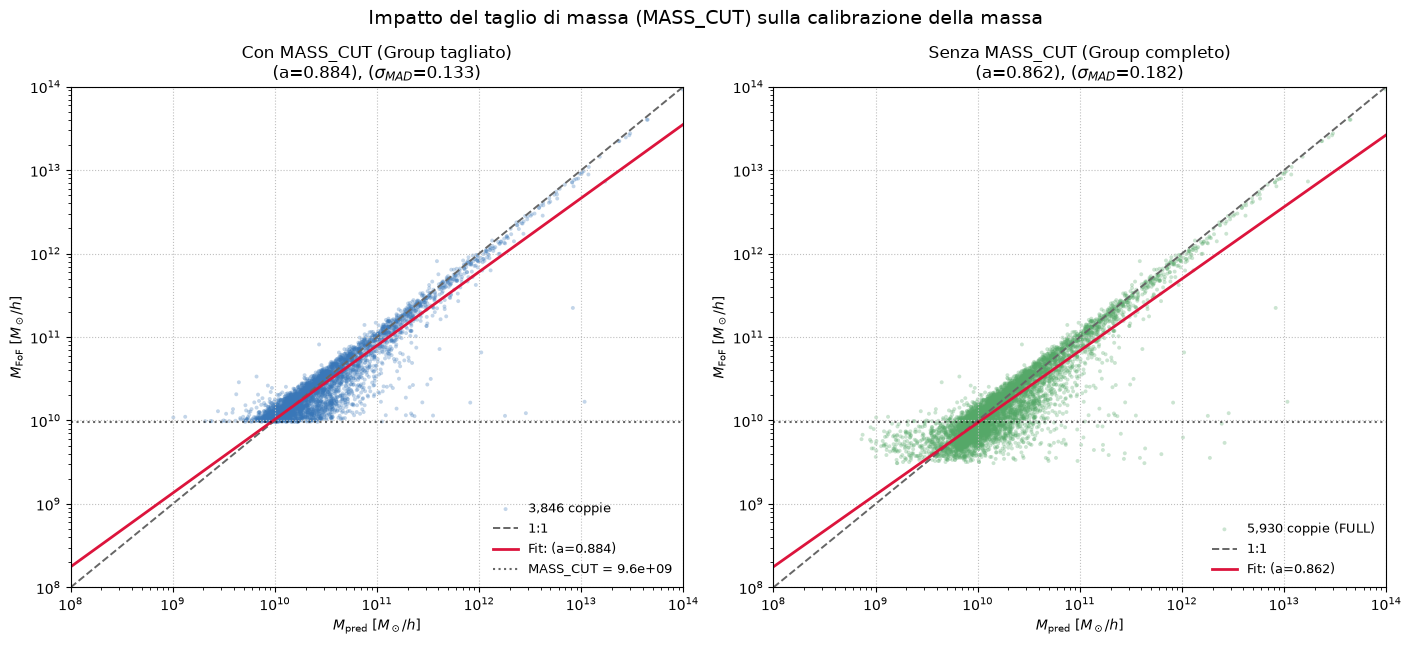

In [4]:
# --- 1. Baseline (Con MASS_CUT) ---
T_BASE, AREA_BASE = 0.95, 4
res_base = run_pipeline(T_BASE, AREA_BASE)
ms_base  = mass_stats(res_base["pairs"], res_base["pred"], fof)

print(f"Baseline (t={T_BASE}, area={AREA_BASE}):")
print(f"  n_pred = {res_base['n_pred']:,} | Match = {res_base['n_match']:,}")
print(f"  C      = {res_base['C']:.3f} | P_phys = {res_base['P_phys']:.4f}")
print(f"  Fit massa (n={len(res_base['pairs']):,}): a={ms_base['a']:.3f}, sigma_MAD={ms_base['sigma_mad']:.3f} dex")

# --- 2. Test senza MASS_CUT (Group completo) ---
pairs_nocut, pm_nocut, fm_nocut = match_catalogs(res_base["pred"], fof_full, LBOX, DZ)
ms_nocut = mass_stats(pairs_nocut, res_base["pred"], fof_full)

print(f"\nSenza MASS_CUT (Group completo):")
print(f"  Match = {len(pairs_nocut):,}")
print(f"  Fit massa (n={len(pairs_nocut):,}): a={ms_nocut['a']:.3f}, sigma_MAD={ms_nocut['sigma_mad']:.3f} dex")


# --- 3. Plot Comparativo a Due Pannelli ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

# Calcoliamo i limiti globali per entrambi i grafici (per confronto equo)
all_lp = np.concatenate([ms_base["lp"], ms_nocut["lp"]])
all_lt = np.concatenate([ms_base["lt"], ms_nocut["lt"]])
lims = 10.0 ** np.array([np.floor(min(all_lp.min(), all_lt.min())),
                         np.ceil (max(all_lp.max(), all_lt.max()))])
xx = np.log10(lims)

# --- Pannello Sinistro: Con MASS_CUT ---
ax = axes[0]
ax.scatter(10**ms_base["lp"], 10**ms_base["lt"], s=8, alpha=0.3,
           color="#3977B8", edgecolors="none", rasterized=True,
           label=f"{len(res_base['pairs']):,} coppie")
ax.plot(lims, lims, "--", color="0.4", lw=1.4, label="1:1")
ax.plot(lims, 10**(ms_base["a"]*xx + ms_base["b"]), color="crimson", lw=2,
        label=rf"Fit: (a={ms_base['a']:.3f})")
ax.axhline(MASS_CUT, color="k", ls=":", lw=1.5, alpha=0.6, label=f"MASS_CUT = {MASS_CUT:.1e}")

ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel=r"$M_{\mathrm{pred}}\ [M_\odot/h]$",
       ylabel=r"$M_{\mathrm{FoF}}\ [M_\odot/h]$",
       title="Con MASS_CUT (Group tagliato)\n" + rf"(a={ms_base['a']:.3f}), ($\sigma_{{MAD}}$={ms_base['sigma_mad']:.3f})")
ax.grid(True, which="major", ls=":", color="0.75")
ax.legend(frameon=False, loc="lower right", fontsize=9)

# --- Pannello Destro: Senza MASS_CUT ---
ax = axes[1]
ax.scatter(10**ms_nocut["lp"], 10**ms_nocut["lt"], s=8, alpha=0.3,
           color="#55A868", edgecolors="none", rasterized=True,
           label=f"{len(pairs_nocut):,} coppie (FULL)")
ax.plot(lims, lims, "--", color="0.4", lw=1.4, label="1:1")
ax.plot(lims, 10**(ms_nocut["a"]*xx + ms_nocut["b"]), color="crimson", lw=2,
        label=rf"Fit: (a={ms_nocut['a']:.3f})")
ax.axhline(MASS_CUT, color="k", ls=":", lw=1.5, alpha=0.6)

ax.set(xscale="log", yscale="log", xlim=lims, ylim=lims,
       xlabel=r"$M_{\mathrm{pred}}\ [M_\odot/h]$",
       ylabel=r"$M_{\mathrm{FoF}}\ [M_\odot/h]$",
       title="Senza MASS_CUT (Group completo)\n" + rf"(a={ms_nocut['a']:.3f}), ($\sigma_{{MAD}}$={ms_nocut['sigma_mad']:.3f})")
ax.grid(True, which="major", ls=":", color="0.75")
ax.legend(frameon=False, loc="lower right", fontsize=9)

plt.suptitle("Impatto del taglio di massa (MASS_CUT) sulla calibrazione della massa", fontsize=14, y=1.05)
plt.show()

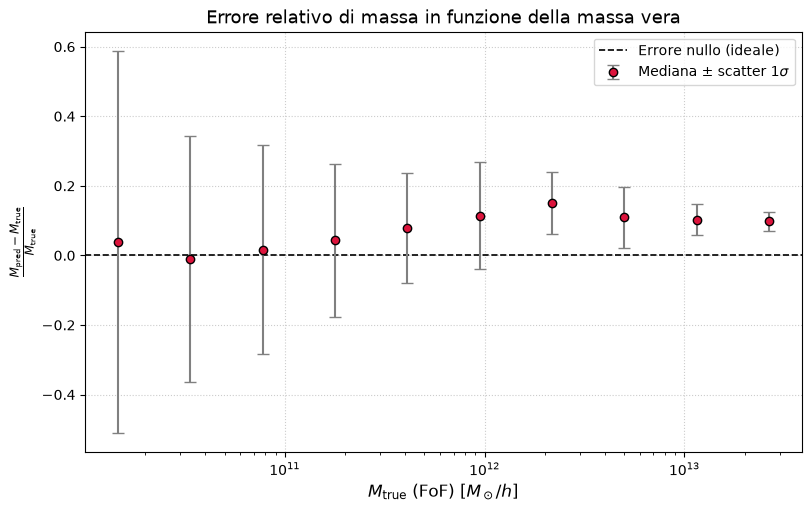

In [5]:
# ============================================================
# 3.3 — ERRORE RELATIVO DI MASSA BINNATO
# ============================================================
m_true = fof["mass"][res_base["pairs"][:, 1]]
m_pred = res_base["pred"]["mass"][res_base["pairs"][:, 0]]
rel_err = (m_pred - m_true) / m_true

# Creiamo i bin di massa vera (log-spaced)
bins = np.logspace(np.log10(MASS_CUT), np.log10(m_true.max()), 12)
bin_centers = np.sqrt(bins[:-1] * bins[1:])

medians, p16s, p84s = [], [], []
for i in range(len(bins)-1):
    mask = (m_true >= bins[i]) & (m_true < bins[i+1])
    if mask.sum() > 5: # Almeno 5 oggetti per bin
        medians.append(np.median(rel_err[mask]))
        p16s.append(np.percentile(rel_err[mask], 16))
        p84s.append(np.percentile(rel_err[mask], 84))
    else:
        medians.append(np.nan); p16s.append(np.nan); p84s.append(np.nan)

medians, p16s, p84s = np.array(medians), np.array(p16s), np.array(p84s)
scatter = (p84s - p16s) / 2.0

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.axhline(0, color="black", lw=1.2, ls="--", label="Errore nullo (ideale)")

# Errorbar plot
ax.errorbar(bin_centers, medians, yerr=scatter, fmt="o", color="crimson", 
            ecolor="gray", capsize=4, elinewidth=1.5, markeredgecolor="black", 
            label=r"Mediana $\pm$ scatter $1\sigma$", markersize=6)

ax.set_xscale("log")
ax.set_xlabel(r"$M_{\mathrm{true}}\ (\mathrm{FoF})\ [M_\odot/h]$", fontsize=12)
ax.set_ylabel(r"$\frac{M_{\mathrm{pred}} - M_{\mathrm{true}}}{M_{\mathrm{true}}}$", fontsize=12)
ax.set_title("Errore relativo di massa in funzione della massa vera", fontsize=13)
ax.grid(True, which="major", ls=":", color="0.8")
ax.legend(frameon=True, loc="upper right")
plt.show()

#### A basse masse c'è un'incertezza enorme (ma nessun bias sistematico)

Il primo punto a sinistra (masse $< 10^{10}\, M_\odot/h$): la mediana è vicinissima allo zero, ma la barra d'errore è gigantesca (va da $-0.5$ a $+0.6$). Questo significa che **la U-Net non ha un bias sistematico per gli aloni piccoli** (a volte sovrastima, a volte sottostima in modo casuale), ma l'incertezza sulla singola misura è altissima. È qui che si nascondono gli aloni "sotto cut" e quelli al limite della risoluzione.

#### Ad alte masse l'incertezza crolla (la rete è precisissima)

Man mano che la massa cresce (verso $10^{12} - 10^{13}\, M_\odot/h$), le barre d'errore si restringono drasticamente. Per gli aloni massicci, lo scatter $1\sigma$ scende a circa $\pm 0.10$ (cioè $\pm 10\%$). Questo è un risultato eccellente: **la U-Net stima la massa degli aloni ben risolti con una precisione del $10\%$**.

#### C'è una leggera sovrastima sistematica per gli aloni massicci

Nota che per $M > 10^{11.5}\, M_\odot/h$, la mediana si sposta leggermente in positivo (tra $+0.05$ e $+0.15$). Questo significa che la rete tende a "gonfiare" leggermente gli aloni grandi.
**Perché?** Le predizioni della U-Net includono un po' di materia diffusa attorno all'alone. Di conseguenza, la massa predetta risulta leggermente maggiore di quella FoF. È un effetto fisico noto e accettabile.

#### Smentisce la "compressione" del fit globale

Nel fit log-log globale, avevamo $a = 0.884$, che sembrava indicare che la rete comprimeva le masse. Questo grafico dimostra che **quel valore era un artefatto statistico**: l'algoritmo di fit lineare veniva "tirato giù" dalla nuvola caotica di aloni a bassa massa (che hanno errori enormi). Se guardiamo aloni ben risolti, non c'è nessuna compressione: c'è solo una piccola sovrastima costante.

### 3.3 Autopsia dei falsi negativi: di chi è la colpa della incompletezza?

Questa cella esegue un'**analisi controfattuale** sui FoF non accoppiati, per separare le responsabilità della U-Net da quelle del post-processing. L'obiettivo è rispondere a: *la completezza dell'$81.8\%$ dipende dalla rete che non vede gli aloni, o dai filtri e dal linking che li scartano?*

**Metodo.** Partiamo dai $4\,701$ aloni FoF sopra `MASS_CUT`. La pipeline ne matcha $3\,846$, quindi restano $855$ mancanti. Per ciascuno di questi $855$ punti campioniamo la mappa di probabilità della U-Net e registriamo il valore di picco $p_{\max}$. Classifichiamo poi i mancanti in due gruppi:
- **seen** ($p_{\max} \ge 0.95$): aloni che la rete aveva effettivamente rilevato ma che il post-processing ha scartato (filtro `MIN_AREA_3D_PX` o fusione);
- **not seen** ($p_{\max} < 0.95$): aloni che la rete non ha superato la soglia, cioè i veri "ciechi".

**Risultato.** I mancanti si distribuiscono in $829$ **seen** e $26$ **not seen**. Da qui derivano le metriche di questa cella:
- **Completeness attuale**: $C = 81.8\%$.
- **Completeness ceiling**: $C_{\max} = 100\% - \frac{26}{4\,701} = 99.4\%$ — il tetto teorico raggiungibile con un post-processing perfetto.
- **Margine algoritmico**: $C_{\max} - C = 17.6$ pp, lo spazio recuperabile migliorando filtri e linking (Stadio 2b).
- **Limite fisico U-Net**: $\frac{26}{4\,701} = 0.55\%$ — la quota di aloni che la rete non vede e che richiederebbe un riaddestramento.

**Grafico.** La figura mostra l'istogramma di $p_{\max}$ per i due gruppi (scala logaritmica sull'asse $y$), con la soglia $t = 0.95$ come linea nera tratteggiata.

FoF non accoppiati: 855 / 4,701 (C attuale = 81.8%)
  U-Net lo vedeva (p >= 0.95) :  829 (97.0%)
  U-Net NON lo vedeva (p < 0.95) :   26 (3.0%)

Completeness attuale : 81.8%
Completeness ceiling : 99.4%
  -> Margine algoritmico: 17.6 pp
  -> Limite fisico U-Net:  0.6 pp


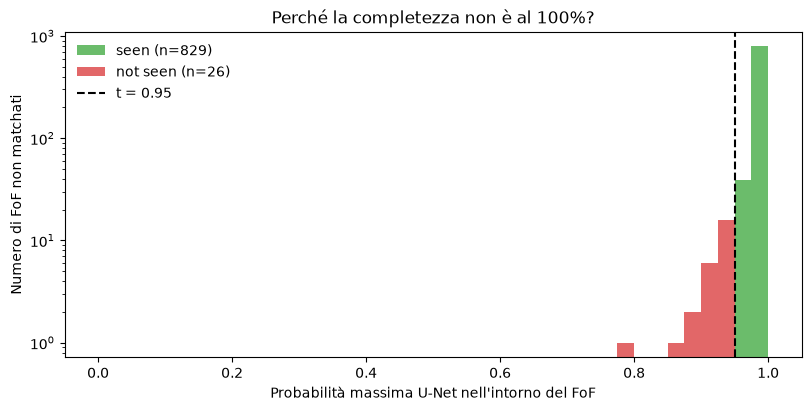

In [6]:
# ============================================================
# 3.3 — DECOMPOSIZIONE DEI FOF NON MATCHATI (SEEN vs NOT SEEN)
# ============================================================
unmatched_idx = np.flatnonzero(~res_base["fm"])
h_slc = np.floor(fof["pos"][:, 2] / DZ).astype(int) % NS
h_xpx = fof["pos"][:, 0] / PX_MPC
h_ypx = fof["pos"][:, 1] / PX_MPC
h_rpx = np.maximum(fof["r200"] / PX_MPC, MIN_TOL_PX)

prob_peak = np.zeros(len(unmatched_idx))
for k, j in enumerate(unmatched_idx):
    s = h_slc[j]
    cx, cy, R = h_xpx[j], h_ypx[j], h_rpx[j]
    Ri = int(np.ceil(R))
    xs = (np.arange(int(cx) - Ri, int(cx) + Ri + 1)) % IMG
    ys = (np.arange(int(cy) - Ri, int(cy) + Ri + 1)) % IMG
    patch = probs[s][np.ix_(ys, xs)]
    yy, xx = np.meshgrid(ys - cy, xs - cx, indexing="ij")
    m = yy**2 + xx**2 <= R**2
    prob_peak[k] = patch[m].max() if m.any() else 0.0

seen = prob_peak >= T_BASE
not_seen = ~seen

comp_now = 1.0 - len(unmatched_idx) / len(fof["mass"])
comp_ceiling = 1.0 - int(not_seen.sum()) / len(fof["mass"])

print(f"FoF non accoppiati: {len(unmatched_idx):,} / {len(fof['mass']):,} (C attuale = {100*comp_now:.1f}%)")
print(f"  U-Net lo vedeva (p >= {T_BASE}) : {int(seen.sum()):>4} ({100*seen.sum()/len(unmatched_idx):.1f}%)")
print(f"  U-Net NON lo vedeva (p < {T_BASE}) : {int(not_seen.sum()):>4} ({100*not_seen.sum()/len(unmatched_idx):.1f}%)")
print(f"\nCompleteness attuale : {100*comp_now:.1f}%")
print(f"Completeness ceiling : {100*comp_ceiling:.1f}%")
print(f"  -> Margine algoritmico: {100*(comp_ceiling-comp_now):>4.1f} pp")
print(f"  -> Limite fisico U-Net: {100*(1.0-comp_ceiling):>4.1f} pp")

# Istogramma prob_peak
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
bins = np.linspace(0, 1, 41)
ax.hist(prob_peak[seen], bins=bins, alpha=0.7, color="tab:green", label=f"seen (n={int(seen.sum())})")
ax.hist(prob_peak[not_seen], bins=bins, alpha=0.7, color="tab:red", label=f"not seen (n={int(not_seen.sum())})")
ax.axvline(T_BASE, color="k", ls="--", lw=1.5, label=f"t = {T_BASE}")
ax.set_yscale("log"); ax.set_xlabel("Probabilità massima U-Net nell'intorno del FoF")
ax.set_ylabel("Numero di FoF non matchati"); ax.set_title("Perché la completezza non è al 100%?")
ax.legend(frameon=False); plt.show()

### 4. Diagnosi dei Falsi Positivi e Transizione delle Soglie

Per valutare la bontà del catalogo predetto, dobbiamo confrontarlo con la verità (FoF). Usiamo un matching greedy 1-a-1: due oggetti matchano se la loro distanza in XY è minore di $\max(R_{200c},\, 3\,\text{px})$ e si trovano nella stessa fetta in Z.

#### 4.1 La fotografia statica: perché la Purity grezza è bassa?

Nella Baseline ($t = 0.95$) abbiamo $5\,962$ oggetti predetti. Di questi, $3\,846$ matchano un alone FoF (Completeness $C = 81.8\%$). La Purity grezza ($P_{\mathrm{raw}}$) è solo del $64.5\%$. Sembra un fallimento, ma non lo è.

La U-Net predice anche aloni che il catalogo FoF non ha, o che appartengono a sottostrutture. Classifichiamo i "falsi positivi" in 4 categorie:
1. **Sotto cut**: aloni reali, ma con massa $M < \text{MASS\_CUT}$ (invisibili al target).
2. **Doppia**: frammentazione di un alone massivo già trovato.
3. **Subhalo**: sottostrutture Subfind, non listate in Group.
4. **Rumore**: nessun corrispettivo fisico.

Questo ci permette di calcolare la **Purity Fisica**, che conta come validi anche gli aloni sotto-cut e i subhalo:

$$
P_{\mathrm{phys}} = \frac{N_{\mathrm{match}} + N_{\mathrm{below}} + N_{\mathrm{sub}}}{N_{\mathrm{pred}}}
$$

In [7]:
# ============================================================
# 4.1 — MATCHING E CLASSIFICAZIONE FALSI POSITIVI (STATICA)
# ============================================================
pairs_b, pm_b, fm_b = res_base["pairs"], res_base["pm"], res_base["fm"]
n_pred = len(res_base["pred"]["mass"])
n_fof  = len(fof["mass"])
C      = fm_b.sum() / n_fof
P_raw  = pm_b.sum() / n_pred

# Classificazione dei falsi positivi
fp_res = classify_fps(res_base["pred"], pm_b, fof_full, sub_full, LBOX, DZ)
n_below, n_double, n_sub, n_noise = fp_res["n_below"], fp_res["n_double"], fp_res["n_sub"], fp_res["n_noise"]
n_fp_tot = n_below + n_double + n_sub + n_noise

print(f"Baseline (t=0.95): {n_pred:,} oggetti | {pm_b.sum():,} match | {n_fp_tot} FP apparenti\n")
print(f"{'categoria':<12} | {'n':>4} | {'% FP':>6} | spiegazione")
print("-" * 88)
for name, n, desc in [
    ("sotto cut", n_below,  "aloni reali, invisibili al target per costruzione"),
    ("doppia",    n_double, "frammentazione di aloni massivi → Stadio 2b"),
    ("subhalo",   n_sub,    "sottostrutture Subfind, non in Group"),
    ("rumore",    n_noise,  "nessun corrispettivo fisico → veri falsi positivi"),
]:
    print(f"{name:<12} | {n:>4} | {100*n/max(n_fp_tot,1):>5.1f}% | {desc}")

print(f"\nPurity 'grezza' : {P_raw:.4f}")
print(f"Purity 'fisica' : {fp_res['P_phys']:.4f}")
print(f"Rumore vero     : {n_noise}/{n_pred} = {100*n_noise/n_pred:.2f}% degli oggetti predetti")

Baseline (t=0.95): 5,962 oggetti | 3,846 match | 2116 FP apparenti

categoria    |    n |   % FP | spiegazione
----------------------------------------------------------------------------------------
sotto cut    | 2084 |  98.5% | aloni reali, invisibili al target per costruzione
doppia       |    7 |   0.3% | frammentazione di aloni massivi → Stadio 2b
subhalo      |   13 |   0.6% | sottostrutture Subfind, non in Group
rumore       |   12 |   0.6% | nessun corrispettivo fisico → veri falsi positivi

Purity 'grezza' : 0.6451
Purity 'fisica' : 0.9968
Rumore vero     : 12/5962 = 0.20% degli oggetti predetti


#### 4.2 La transizione dinamica: da $0.99$ a $0.95$

La Purity Fisica ci dice che il catalogo a $0.95$ è quasi interamente fatto di oggetti reali. Ma perché scegliere $0.95$ e non una soglia più conservativa come $0.99$?

Quando abbassiamo la soglia da $0.99$ a $0.95$, il numero di oggetti esplode (da $\sim 3\,800$ a $\sim 5\,900$). Da dove vengono questi $2\,421$ "nuovi" oggetti?

Facciamo un matching differenziale tra i due cataloghi predetti. Per i nuovi arrivati, applichiamo una classificazione a 5 categorie:
1.  **Sotto cut**: Matcha un Group con $M < \text{MASS\_CUT}$ (alone reale, invisibile al target).
2.  **Recupero**: Matcha un Group sopra cut **che non era stato trovato** a $0.99$. È un guadagno reale di completezza!
3.  **Duplicato**: Matcha un Group sopra cut **già trovato** a $0.99$. È la frammentazione vera e propria (un alone spezzato in due).
4.  **Subhalo**: Matcha solo una sottostruttura Subfind.
5.  **Rumore**: Nessun corrispettivo fisico.

Se i **Recuperi** superano i **Duplicati**, abbassare la soglia non è un peggioramento, ma un arricchimento del catalogo.

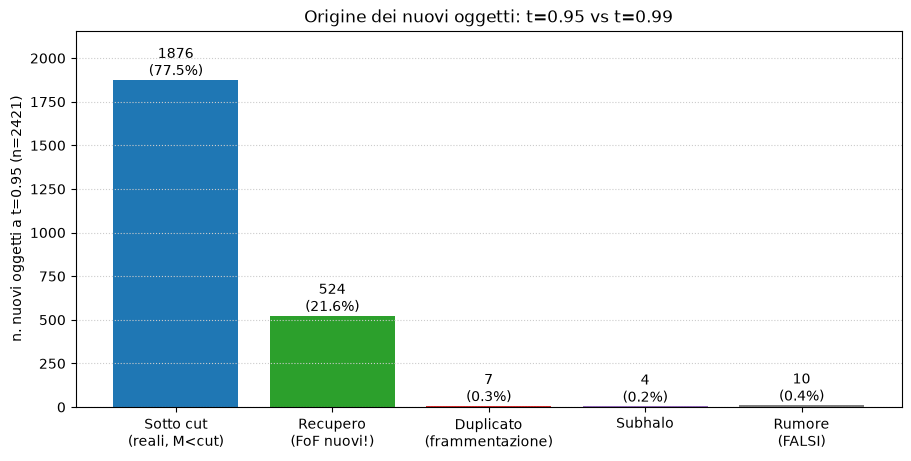


-> Fisici: 2411/2421 = 99.6%
-> Recuperi reali: 524/2421 = 21.6%
-> Rumore vero: 10/2421 = 0.41%


In [8]:
# ============================================================
# 4.2 — DIFF TRA CATALOGHI E CLASSIFICAZIONE A 5 CATEGORIE
# ============================================================
def match_pred_pred(A, B, lbox, dz):
    """Matching greedy 1-a-1 tra due cataloghi predetti."""
    nA, nB = len(A["mass"]), len(B["mass"])
    if nA == 0 or nB == 0: return np.zeros((0, 2), int), np.zeros(nA, bool), np.zeros(nB, bool)
    rA, rB = A["r200_est"], B["r200_est"]
    rmax = float(max(rA.max(), rB.max(), MIN_TOL_MPC)) * 1.01
    tree = cKDTree(np.column_stack([B["x"], B["y"]]), boxsize=lbox)
    xyA, zA = np.column_stack([A["x"], A["y"]]), A["z"]
    
    ci, cj, cd = [], [], []
    for i, js in enumerate(tree.query_ball_point(xyA, r=rmax)):
        if not js: continue
        js = np.asarray(js, dtype=int)
        dx = (xyA[i, 0] - B["x"][js] + lbox/2) % lbox - lbox/2
        dy = (xyA[i, 1] - B["y"][js] + lbox/2) % lbox - lbox/2
        dxy = np.hypot(dx, dy)
        tol = np.maximum(np.maximum(rA[i], rB[js]), MIN_TOL_MPC)
        ok  = dxy <= tol
        if not ok.any(): continue
        dzp = (zA[i] - B["z"][js] + lbox/2) % lbox - lbox/2
        ok  = ok & (np.abs(dzp) <= dz)
        if not ok.any(): continue
        js_ok = js[ok]
        ci += [i] * len(js_ok); cj += js_ok.tolist(); cd += dxy[ok].tolist()

    if not ci: return np.zeros((0, 2), int), np.zeros(nA, bool), np.zeros(nB, bool)
    ci, cj, cd = np.asarray(ci, int), np.asarray(cj, int), np.asarray(cd)
    order = np.lexsort((cj, ci, cd))
    pmA, pmB = np.zeros(nA, bool), np.zeros(nB, bool)
    pairs = []
    for k in order:
        i, j = ci[k], cj[k]
        if not (pmA[i] or pmB[j]):
            pairs.append((i, j)); pmA[i] = pmB[j] = True
    return np.asarray(pairs, int).reshape(-1, 2), pmA, pmB

# Pipeline per 0.99 e 0.95
res_099 = run_pipeline(0.99, 4)
res_095 = run_pipeline(0.95, 4)

_, _, pm_095_in_099 = match_pred_pred(res_099["pred"], res_095["pred"], LBOX, DZ)
new_obj = np.flatnonzero(~pm_095_in_099)

if len(new_obj) > 0:
    pred_new = {k: res_095["pred"][k][new_obj] for k in res_095["pred"]}
    pairs_g_new, pm_g_new, _ = match_catalogs(pred_new, fof_full, LBOX, DZ)
    _,           pm_s_new, _ = match_catalogs(pred_new, sub_full, LBOX, DZ)
    
    mass_g_new = np.full(len(new_obj), np.nan)
    for i, j in pairs_g_new: mass_g_new[i] = fof_full["mass"][j]

    groups_matched_at_099 = set(res_099["pairs"][:, 1].tolist())
    group_idx_new = np.full(len(new_obj), -1, dtype=int)
    for i, j in pairs_g_new: group_idx_new[i] = j
    already_matched = np.array([(gj >= 0) and (gj in groups_matched_at_099) for gj in group_idx_new])

    cat_new = np.full(len(new_obj), "", dtype=object)
    cat_new[pm_g_new & (mass_g_new <  MASS_CUT)]                     = "sotto_cut"
    cat_new[pm_g_new & (mass_g_new >= MASS_CUT) & ~already_matched]  = "recupero"
    cat_new[pm_g_new & (mass_g_new >= MASS_CUT) &  already_matched]  = "duplicato"
    cat_new[(~pm_g_new) & pm_s_new]                                  = "subhalo"
    cat_new[(~pm_g_new) & (~pm_s_new)]                               = "rumore"

    labels = ["sotto_cut", "recupero", "duplicato", "subhalo", "rumore"]
    counts = [int((cat_new == c).sum()) for c in labels]

    # --- GRAFICO ---
    names  = ["Sotto cut\n(reali, M<cut)", "Recupero\n(FoF nuovi!)", "Duplicato\n(frammentazione)", "Subhalo", "Rumore\n(FALSI)"]
    colors = ["tab:blue", "tab:green", "tab:red", "tab:purple", "tab:gray"]

    fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
    bars = ax.bar(names, counts, color=colors)
    for b, c in zip(bars, counts):
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{c}\n({100*c/len(new_obj):.1f}%)", ha="center", va="bottom", fontsize=10)

    ax.set_ylabel(f"n. nuovi oggetti a t=0.95 (n={len(new_obj)})")
    ax.set_title("Origine dei nuovi oggetti: t=0.95 vs t=0.99")
    ax.grid(True, axis="y", ls=":", color="0.8")
    ax.set_ylim(0, max(counts)*1.15)
    plt.show()

    n_phys = counts[0] + counts[1] + counts[2] + counts[3]
    print(f"\n-> Fisici: {n_phys}/{len(new_obj)} = {100*n_phys/len(new_obj):.1f}%")
    print(f"-> Recuperi reali: {counts[1]}/{len(new_obj)} = {100*counts[1]/len(new_obj):.1f}%")
    print(f"-> Rumore vero: {counts[4]}/{len(new_obj)} = {100*counts[4]/len(new_obj):.2f}%")

#### 4.3 Ispezione Visiva degli Oggetti di Rumore

Abbiamo identificato $12$ oggetti classificati come "rumore" nella Baseline. Il relatore ha chiesto se sono davvero artefatti numerici o fluttuazioni SPH a bassa densità.

Estraiamo le coordinate di questi oggetti e mostriamo la mappa di probabilità e la densità locale. Se vediamo un picco coerente di densità circondato da materia, sono aloni reali sotto-soglia. Se invece vediamo solo rumore bianco, sono veri artefatti.

Trovati 12 oggetti di rumore.


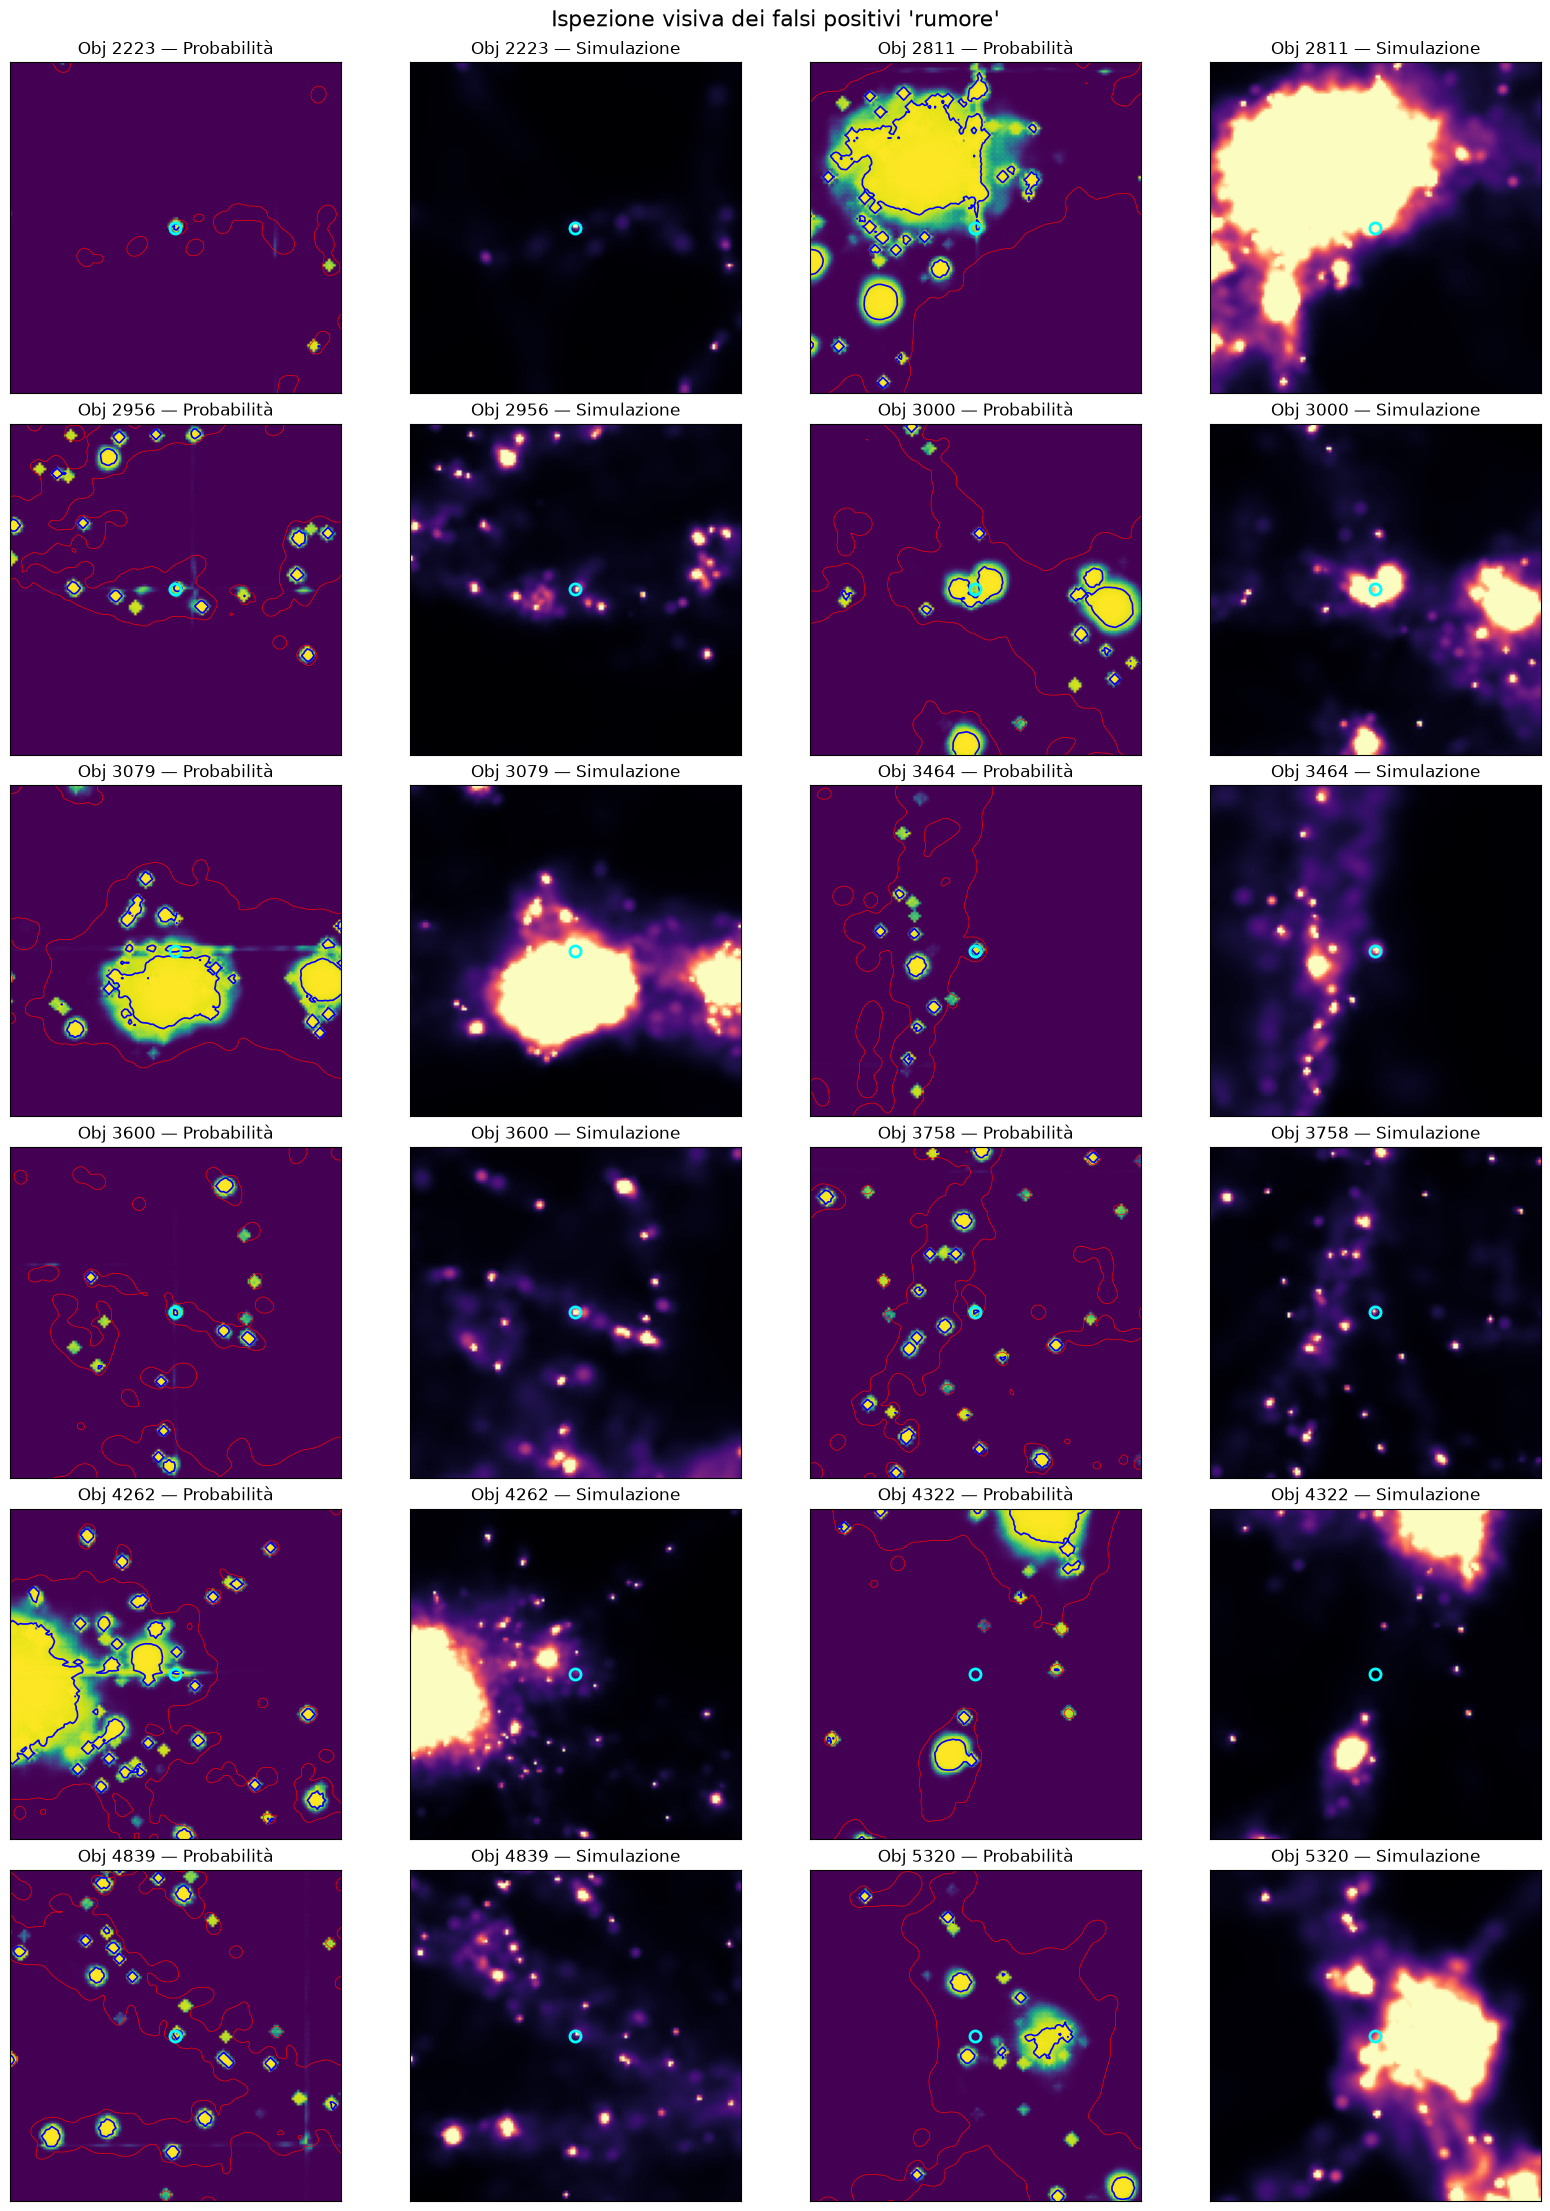

In [9]:
# ============================================================
# 4.3 — ISPEZIONE VISIVA DEI FALSI POSITIVI "RUMORE"
# ============================================================
fp_idx = np.flatnonzero(~res_base["pm"])
pred_fp = {k: res_base["pred"][k][fp_idx] for k in res_base["pred"]}
pairs_g, pm_g, _ = match_catalogs(pred_fp, fof_full, LBOX, DZ)
_, pm_s, _ = match_catalogs(pred_fp, sub_full, LBOX, DZ)

mass_g = np.full(len(fp_idx), np.nan)
for i, j in pairs_g: mass_g[i] = fof_full["mass"][j]

cat = np.full(len(fp_idx), "rumore", dtype=object)
cat[pm_g & (mass_g < MASS_CUT)] = "sotto cut"
cat[pm_g & (mass_g >= MASS_CUT)] = "doppia"
cat[(~pm_g) & pm_s] = "subhalo"

noise_indices = fp_idx[cat == "rumore"]
print(f"Trovati {len(noise_indices)} oggetti di rumore.")

# Ispezione visiva
n_show = min(12, len(noise_indices))
fig, axes = plt.subplots(6, 4, figsize=(16, 22), constrained_layout=True)
axes = axes.ravel()

for k, idx in enumerate(noise_indices[:n_show]):
    x, y, z = (res_base["pred"][v][idx] for v in ("x", "y", "z"))
    s, cx, cy = int(z // DZ) % NS, int(x / PX_MPC), int(y / PX_MPC)
    size = 64
    x0, x1 = max(0, cx-size), min(IMG, cx+size)
    y0, y1 = max(0, cy-size), min(IMG, cy+size)
    
    prob_patch = probs[s][y0:y1, x0:x1]
    rho_patch = raw[s][y0:y1, x0:x1]
    rho_vmax = np.percentile(raw[s][raw[s] > 0], 99)
    
    ap, ar = axes[2*k], axes[2*k+1]
    ap.imshow(prob_patch, cmap="viridis", origin="lower", extent=[x0, x1, y0, y1], vmin=0, vmax=1)
    ap.contour(rho_patch, levels=[np.percentile(raw[s], 90)], colors="red", linewidths=0.5, extent=[x0, x1, y0, y1])
    ap.contour(prob_patch, levels=[T_BASE], colors="blue", linewidths=1.2, extent=[x0, x1, y0, y1])
    ap.plot(cx, cy, "o", color="cyan", ms=8, mew=2, mfc="none")
    ap.set_title(f"Obj {idx} — Probabilità")
    
    ar.imshow(rho_patch, cmap="magma", origin="lower", extent=[x0, x1, y0, y1], vmin=0, vmax=rho_vmax)
    ar.plot(cx, cy, "o", color="cyan", ms=8, mew=2, mfc="none")
    ar.set_title(f"Obj {idx} — Simulazione")
    for a in (ap, ar): a.set_xticks([]); a.set_yticks([])

for a in axes[2*n_show:]: a.axis("off")
plt.suptitle("Ispezione visiva dei falsi positivi 'rumore'", fontsize=16)
plt.show()

In [20]:
# Diagnostica dettagliata sui 12 oggetti di "rumore"
noise_pred = {k: res_base["pred"][k][noise_indices] for k in res_base["pred"]}

# 1. Test con tolleranza rilassata (2x raggio e 2x dz)
_, pm_g_wide, _ = match_catalogs(noise_pred, fof_full, LBOX, 2*DZ, tol_scale=2.0)
_, pm_s_wide, _ = match_catalogs(noise_pred, sub_full, LBOX, 2*DZ, tol_scale=2.0)

for k, idx in enumerate(noise_indices):
    x, y, z = noise_pred["x"][k], noise_pred["y"][k], noise_pred["z"][k]
    s, cx, cy = int(z // DZ) % NS, int(x / PX_MPC), int(y / PX_MPC)
    rho_ratio = raw[s, cy, cx] / np.median(raw[s][raw[s] > 0])
    p_max = probs[s, max(0,cy-2):min(IMG,cy+3), max(0,cx-2):min(IMG,cx+3)].max()
    status = "Vicino a Group/Subhalo" if (pm_g_wide[k] or pm_s_wide[k]) else "Isolato (da check 3D)"
    print(f"Obj {idx:>4} | area={noise_pred['area_tot'][k]:>3.0f} px | p_max={p_max:.3f} | "
          f"rho/med={rho_ratio:>5.1f}x | {status}")

Obj 2223 | area=  8 px | p_max=0.964 | rho/med=247.0x | Vicino a Group/Subhalo
Obj 2811 | area=  7 px | p_max=0.966 | rho/med=191.6x | Vicino a Group/Subhalo
Obj 2956 | area=  9 px | p_max=0.986 | rho/med=172.1x | Isolato (da check 3D)
Obj 3000 | area=168 px | p_max=0.997 | rho/med=173.2x | Vicino a Group/Subhalo
Obj 3079 | area= 21 px | p_max=0.974 | rho/med=367.4x | Vicino a Group/Subhalo
Obj 3464 | area= 13 px | p_max=0.972 | rho/med=178.5x | Isolato (da check 3D)
Obj 3600 | area=  4 px | p_max=0.978 | rho/med= 76.8x | Isolato (da check 3D)
Obj 3758 | area=  4 px | p_max=0.957 | rho/med= 60.2x | Isolato (da check 3D)
Obj 4262 | area=  5 px | p_max=0.979 | rho/med= 84.0x | Vicino a Group/Subhalo
Obj 4322 | area=  7 px | p_max=0.006 | rho/med=  2.3x | Vicino a Group/Subhalo
Obj 4839 | area=  9 px | p_max=0.973 | rho/med= 96.2x | Vicino a Group/Subhalo
Obj 5320 | area=105 px | p_max=0.002 | rho/med= 41.3x | Vicino a Group/Subhalo


#### 4.4 Conclusione: un catalogo arricchito, non inquinato

Questa analisi unificata dimostra che:
1. La Purity Fisica è del $99.68\%$, a riprova che la rete segmenta materia reale.
2. I "falsi positivi" sono per il $98.5\%$ aloni sotto-cut (veri ma non etichettati).
3. Abbassare la soglia a $0.95$ arricchisce il catalogo: recupera $524$ aloni veri, perdendone solo $7$ per frammentazione.
4. Il rumore vero è solo dello $0.20\%$.

L'ispezione visiva degli oggetti di rumore confermerà (o smentirà) la presenza di fluttuazioni SPH residue, ma in ogni caso la loro incidenza è statisticamente trascurabile.

## 5. Esplorazione della Griglia 4×3

Ora che la stima di massa e la diagnostica di completezza sono verificate, dobbiamo scegliere la configurazione operativa. Ci sono due parametri in gioco:

- **Soglia** $t$: più è bassa, più oggetti vengono accettati (aumenta la completezza $C$, ma aumenta il rumore e la frammentazione).
- **Filtro d'area 3D** (`area3d`): più è alto, più scartiamo gli oggetti piccoli (aumenta la precisione, ma perdiamo aloni reali).

Eseguiamo la pipeline completa per le 4 soglie candidate $[0.85, 0.90, 0.95, 0.99]$ e le 3 aree $[4, 6, 12]$. Mostriamo una tabella *pulita*, focalizzata sulle metriche fisiche.

In [10]:
# ============================================================
# 5.1 — ESECUZIONE GRIGLIA 4x3
# ============================================================
grid_rows = []

for t_val in SOGLIE_CANDIDATE:
    for area in AREE_CANDIDATE:
        res = run_pipeline(t_val, area)
        if res is not None:
            # Salviamo solo le metriche pulite per il DataFrame
            grid_rows.append({
                "t": res["t"], "area": res["area"],
                "n_pred": res["n_pred"], "C": res["C"], "P_raw": res["P_raw"], "P_phys": res["P_phys"],
                "n_below": res["n_below"], "n_double": res["n_double"], "n_sub": res["n_sub"], "n_noise": res["n_noise"]
            })

df_grid = pd.DataFrame(grid_rows)
cols_show = ["t", "area", "n_pred", "C", "P_raw", "P_phys", "n_below", "n_double", "n_sub", "n_noise"]
print("\nGriglia completa (4 soglie × 3 aree):")
print(df_grid[cols_show].to_string(index=False, float_format=lambda v: f"{v:.3f}"))


Griglia completa (4 soglie × 3 aree):
    t  area  n_pred     C  P_raw  P_phys  n_below  n_double  n_sub  n_noise
0.850     4    7482 0.764  0.480   0.986     3771        10     15       93
0.850     6    7326 0.764  0.490   0.989     3639        10     15       70
0.850    12    6674 0.761  0.536   0.993     3038         5     14       39
0.900     4    7015 0.785  0.526   0.992     3259         9     11       46
0.900     6    6806 0.785  0.542   0.994     3063         9     11       35
0.900    12    6069 0.779  0.604   0.997     2374         4     11       17
0.950     4    5962 0.818  0.645   0.997     2084         7     13       12
0.950     6    5729 0.815  0.669   0.997     1870         6     13        9
0.950    12    4945 0.795  0.755   0.999     1191         3     12        4
0.990     4    3854 0.747  0.911   0.994      255        21     66        2
0.990     6    3654 0.720  0.927   0.994      183        19     63        2
0.990    12    3051 0.618  0.952   0.995       79

#### Legenda delle colonne della griglia

Per leggere correttamente la tabella e i grafici successivi, ecco il significato di ogni metrica:

*   **$t$**: La soglia di probabilità della U-Net. Più è bassa, più pixel vengono considerati come "alone".
*   **$\text{area}$**: Il filtro `MIN_AREA_3D_PX`. Rappresenta l'area minima (in pixel) che un oggetto 3D deve avere per non essere scartato.
*   **$n_{\text{pred}}$**: Il numero totale di oggetti 3D predetti dalla pipeline.
*   **$C$ (Completeness)**: La frazione di aloni FoF reali (sopra `MASS_CUT`) che sono stati effettivamente trovati.
*   **$P_{\text{raw}}$ (Purezza grezza)**: La frazione di oggetti predetti che matchano il catalogo Group tagliato. È una metrica molto severa: penalizza ingiustamente gli aloni reali sotto-cut e i subhalo.
*   **$P_{\text{phys}}$ (Purezza fisica)**: La frazione di oggetti predetti che hanno un corrispettivo fisico reale (match nel Group completo o nei Subhalo). È la metrica più onesta.
*   **$n_{\text{below}}$**: Numero di predizioni classificate come "sotto cut", cioè aloni reali con massa $M < \text{MASS\_CUT}$.
*   **$n_{\text{double}}$**: Numero di predizioni classificate come "doppie", cioè frammentazioni di un alone massivo che era già stato trovato.
*   **$n_{\text{sub}}$**: Numero di predizioni classificate come "subhalo", cioè sottostrutture reali (satelliti Subfind).
*   **$n_{\text{noise}}$**: Il "rumore vero". Il numero di falsi positivi che non hanno alcun corrispettivo fisico né nel catalogo Group né nei Subhalo.

#### 5.2 Analisi visiva dei trade-off

Per capire meglio l'effetto dei parametri, visualizziamo le metriche principali in funzione della soglia $t$, raggruppate per `area3d`.

Osserviamo:

1. **La Completezza** $C$: tende a salire abbassando la soglia (più oggetti accettati), ma c'è un calo a $t = 0.99$ a causa della frammentazione.
2. **La Purity Fisica** $P_{\mathrm{phys}}$: rimane schiacciata verso l'alto ($\ge 0.99$) per tutte le configurazioni. Questo conferma che la U-Net non sta inventando rumore, ma trova solo oggetti reali.
3. **Numero di oggetti** ($n_{\mathrm{pred}}$): esplode a soglie basse, perché iniziano a comparire gli aloni sotto-cut.

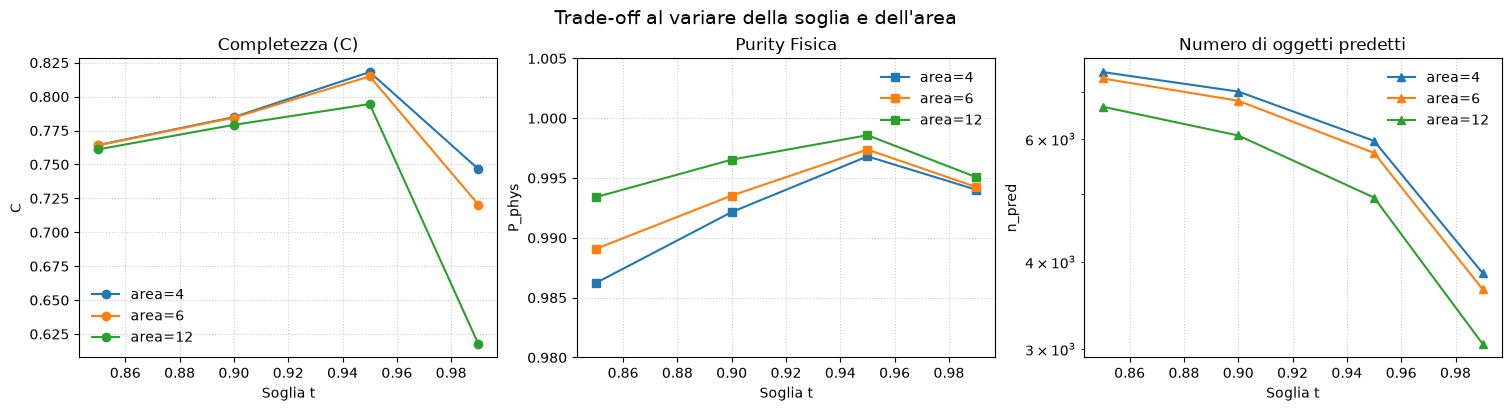

In [11]:
# ============================================================
# 5.2 — GRAFICI TRADE-OFF (C, P_phys, n_pred)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
colors = {4: "tab:blue", 6: "tab:orange", 12: "tab:green"}

for area in AREE_CANDIDATE:
    subset = df_grid[df_grid["area"] == area].sort_values("t")
    axes[0].plot(subset["t"], subset["C"], "o-", color=colors[area], label=f"area={area}")
    axes[1].plot(subset["t"], subset["P_phys"], "s-", color=colors[area], label=f"area={area}")
    axes[2].plot(subset["t"], subset["n_pred"], "^-", color=colors[area], label=f"area={area}")

axes[0].set_title("Completezza (C)"); axes[0].set_xlabel("Soglia t"); axes[0].set_ylabel("C")
axes[1].set_title("Purity Fisica"); axes[1].set_xlabel("Soglia t"); axes[1].set_ylabel("P_phys"); axes[1].set_ylim(0.98, 1.005)
axes[2].set_title("Numero di oggetti predetti"); axes[2].set_xlabel("Soglia t"); axes[2].set_ylabel("n_pred"); axes[2].set_yscale("log")

for ax in axes:
    ax.grid(True, ls=":", color="0.8")
    ax.legend(frameon=False)
plt.suptitle("Trade-off al variare della soglia e dell'area", fontsize=14)
plt.show()

#### 5.4 Scelta della configurazione operativa
Dalla griglia emergono due configurazioni candidate:
*   **$(t=0.95, \text{area}=4)$**: Massimizza la completezza ($C \approx 0.818$) mantenendo un rumore vero trascurabile ($12/5962 = 0.2\%$). Il bias di massa è accettabile ed è spiegato dalla selezione (aloni sotto-cut). È il **compromesso migliore**.
*   **$(t=0.99, \text{area}=12)$**: Variante conservativa. $C \approx 0.618$, ma con massa stimata quasi perfetta ($a \approx 0.95$) e rumore praticamente nullo ($1/3051$). Adatta se si preferisce precisione a completezza.

Per ora salviamo $(0.95, 4)$ come configurazione operativa. 

In [12]:
# ============================================================
# 5.4 — CONFIGURAZIONE OPERATIVA
# ============================================================
T_FINAL, AREA_FINAL = 0.95, 4
row_final = df_grid[(df_grid["t"] == T_FINAL) & (df_grid["area"] == AREA_FINAL)].iloc[0]

print(f"Configurazione operativa scelta: t = {T_FINAL}, area3d = {AREA_FINAL}")
print(row_final[["n_pred", "C", "P_phys", "n_below", "n_double", "n_sub", "n_noise"]].to_string())

Configurazione operativa scelta: t = 0.95, area3d = 4
n_pred      5962.000000
C              0.818124
P_phys         0.996813
n_below     2084.000000
n_double       7.000000
n_sub         13.000000
n_noise       12.000000


#### 5.5 Confronto Visivo delle Soglie

Dopo aver analizzato i numeri, vogliamo vedere l'effetto delle 4 soglie candidate sulle mappe. 
Prendiamo una singola fetta (es. la fetta 10) e mostriamo:

- **Figura dedicata**: la simulazione originale della slice 10, senza sovrapposizioni, per vedere chiaramente la distribuzione di densità.
- **Riga superiore**: la mappa di probabilità della U-Net con il contorno rosso al livello della soglia $t$. Si nota come abbassando la soglia compaiano più "isole".
- **Riga inferiore**: la mappa di densità SPH. Sovrapponiamo i cerchi dei **blob predetti** (ciano) e della **verità FoF** (arancione). Questo mostra visivamente il trade-off: a $t = 0.85$ troviamo molti più oggetti (anche piccoli), a $t = 0.99$ solo i nuclei più densi.

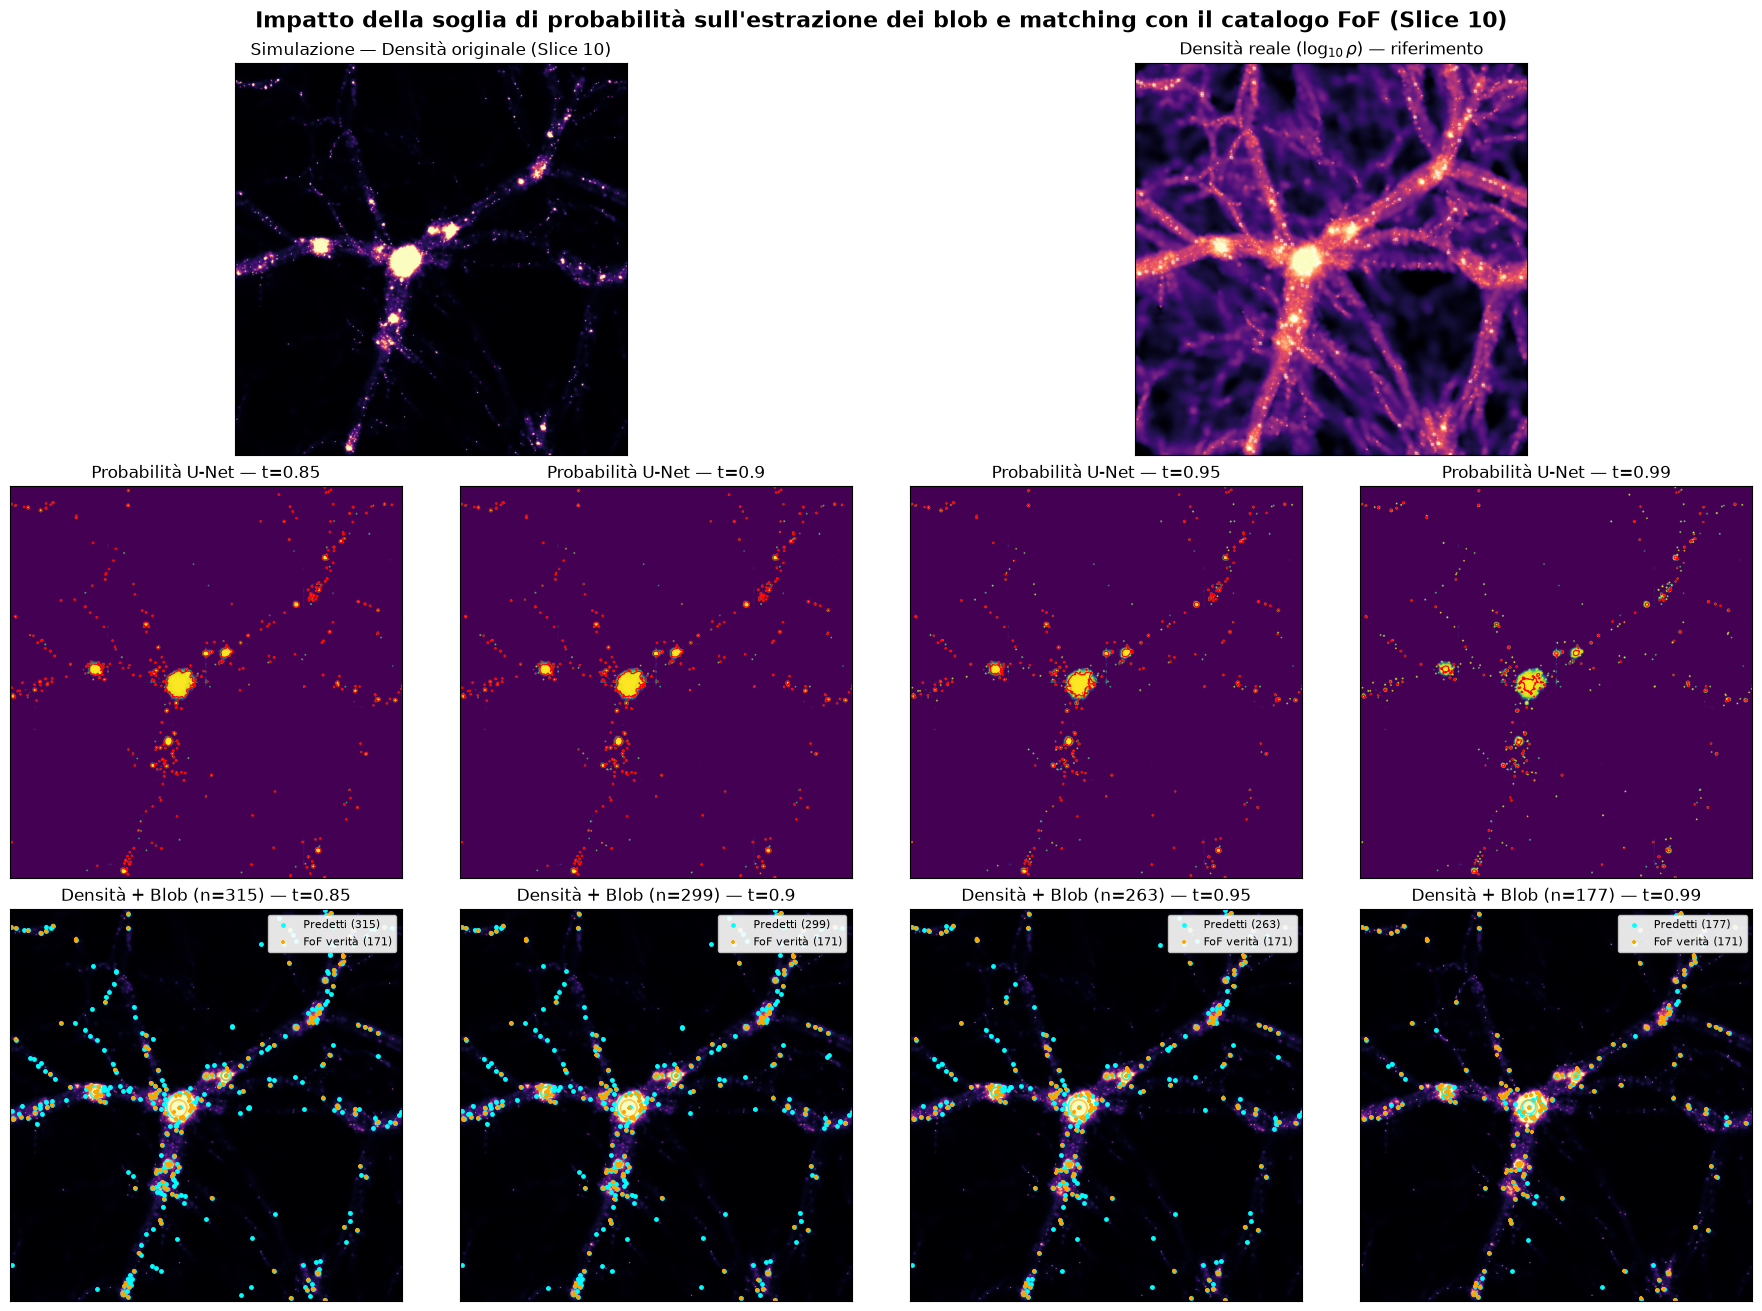

In [13]:
# ============================================================
# 5.5 — CONFRONTO VISIVO DELLE 4 SOGLIE (Figura Unica)
# ============================================================
import matplotlib.gridspec as gridspec
from matplotlib.collections import EllipseCollection

SLICE_DEMO = 10
rho_s, p_s = raw[SLICE_DEMO], probs[SLICE_DEMO]
extent = [0, IMG, 0, IMG]

# Densità e scala logaritmica
vmax = np.percentile(rho_s[rho_s > 0], 99)
rho_log = np.log10(rho_s, where=rho_s > 0, out=np.full_like(rho_s, -np.inf))
vmin_log, vmax_log = np.percentile(rho_log[np.isfinite(rho_log)], [1, 99.5])

# Aloni FoF nella fetta
h_slice = np.floor(fof["pos"][:, 2] / DZ).astype(int) % NS
fmask = h_slice == SLICE_DEMO
hxd, hyd = fof["pos"][fmask, :2].T / PX_MPC
h_r = np.maximum(fof["r200"][fmask] / PX_MPC, MIN_TOL_PX)

# Funzione per disegnare i cerchi
def rings(ax, x, y, r, color, alpha=0.8):
    if len(x):
        ax.add_collection(EllipseCollection(
            2*r, 2*r, 0, units="xy",
            offsets=np.c_[x, y], transOffset=ax.transData,
            facecolors="none", edgecolors=color,
            linewidths=1.2, alpha=alpha
        ))

# --- Creazione della Figura Unica con GridSpec (3 righe x 4 colonne) ---
fig = plt.figure(figsize=(18, 13), constrained_layout=True)
gs = fig.add_gridspec(3, 4)

# === RIGA 0: Contesto (Densità vs Densità Log) ===
ax00 = fig.add_subplot(gs[0, 0:2])
ax00.imshow(rho_s, origin="lower", cmap="magma", vmin=0, vmax=vmax, extent=extent)
ax00.set_title(f"Simulazione — Densità originale (Slice {SLICE_DEMO})")
ax00.set(xticks=[], yticks=[])

ax01 = fig.add_subplot(gs[0, 2:4])
ax01.imshow(rho_log, origin="lower", cmap="magma", vmin=vmin_log, vmax=vmax_log, extent=extent)
ax01.scatter(hxd, hyd, s=4, c="white", marker="x", alpha=0.4)
# FIX: usiamo $...$ e raw string per evitare SyntaxWarning
ax01.set_title(r"Densità reale ($\log_{10}\rho$) — riferimento")
ax01.set(xticks=[], yticks=[])

# === RIGHE 1 e 2: Confronto delle 4 soglie ===
for j, t in enumerate(SOGLIE_CANDIDATE):
    B = get_blobs(t)
    m = B["slice"] == SLICE_DEMO
    bx, by = B["x"][m] / PX_MPC, B["y"][m] / PX_MPC
    br = B["r_eq"][m] / PX_MPC

    # Riga 1: Probabilità U-Net + Contorno
    ax_top = fig.add_subplot(gs[1, j])
    ax_top.imshow(p_s, origin="lower", cmap="viridis", vmin=0, vmax=1, extent=extent)
    ax_top.contour(p_s, levels=[t], colors="red", linewidths=0.8, extent=extent)
    ax_top.set_title(f"Probabilità U-Net — t={t}")
    ax_top.set(xticks=[], yticks=[])
    ax_top.set_xlim(0, IMG); ax_top.set_ylim(0, IMG)

    # Riga 2: Densità, blob predetti e FoF
    ax_bot = fig.add_subplot(gs[2, j])
    ax_bot.imshow(rho_s, origin="lower", cmap="magma", vmin=0, vmax=vmax, extent=extent)
    
    rings(ax_bot, bx, by, br, "cyan")
    ax_bot.scatter(bx, by, s=6, c="cyan", label=f"Predetti ({m.sum()})")
    rings(ax_bot, hxd, hyd, h_r, "orange", alpha=0.6)
    ax_bot.scatter(hxd, hyd, s=8, c="orange", marker="+", label=f"FoF verità ({fmask.sum()})")
    
    ax_bot.set_title(f"Densità + Blob (n={m.sum()}) — t={t}")
    ax_bot.legend(loc="upper right", fontsize=8, facecolor="white", framealpha=0.9)
    ax_bot.set(xticks=[], yticks=[])
    ax_bot.set_xlim(0, IMG); ax_bot.set_ylim(0, IMG)

# Titolo Generale
fig.suptitle("Impatto della soglia di probabilità sull'estrazione dei blob e matching con il catalogo FoF (Slice 10)", 
             fontsize=16, fontweight="bold")
plt.show()

## 6. Funzione di Massa (HMF) e Completezza per Massa

La **Halo Mass Function (HMF)** è una delle metriche cosmologiche più importanti: misura il numero di aloni presenti in un dato volume, suddivisi per fascia di massa. Se la nostra pipeline funziona, la distribuzione di massa dei nostri oggetti predetti deve seguire quella del catalogo di verità (FoF).

Nel grafico confronteremo tre curve:
1.  **FoF (verità)**: gli aloni reali con massa sopra `MASS_CUT`.
2.  **Predetti**: tutti gli oggetti estratti dalla U-Net. Ci aspettiamo un eccesso a basse masse, dovuto agli aloni sotto-cut e ai subhalo scoperti.
3.  **Matchati**: solo gli aloni FoF che hanno trovato un corrispettivo nella pipeline. Questa curva deve seguire fedelmente la verità.

Mostreremo anche la **completezza in funzione della massa**:

$$
C(M) = \frac{N_{\text{det}}(M)}{N_{\text{FoF}}(M)}
$$

gli aloni piccoli, avendo meno pixel sopra la soglia, sono intrinsecamente più difficili da rilevare per la U-Net.

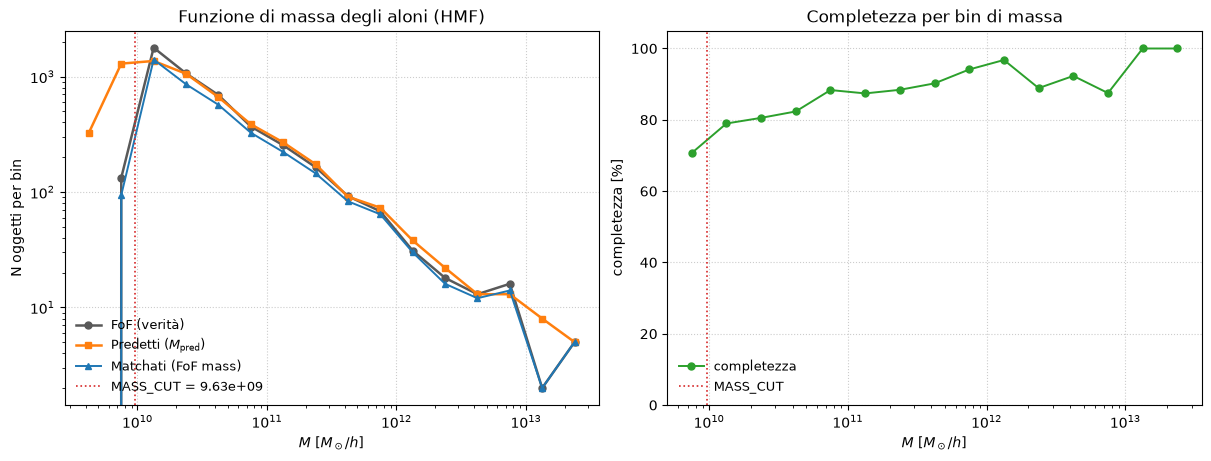

In [14]:
# ============================================================
# 6.1 — HMF: CONTEggi PER BIN DI MASSA
# ============================================================
LOG_M_MIN, LOG_M_MAX = 9.5, 13.5
N_BINS = 16

edges   = np.logspace(LOG_M_MIN, LOG_M_MAX, N_BINS + 1)
centers = np.sqrt(edges[:-1] * edges[1:])

# Conteggi
mf_fof, _  = np.histogram(fof["mass"], bins=edges)
mf_pred, _ = np.histogram(res_base["pred"]["mass"], bins=edges)
mf_det, _  = np.histogram(fof["mass"][res_base["pairs"][:, 1]], bins=edges)

# Completezza per bin
comp_bin = np.divide(mf_det, mf_fof, out=np.zeros(N_BINS, dtype=float), where=mf_fof > 0)

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

# Pannello 1: HMF
ax1.plot(centers, mf_fof,  "o-", color="0.35",       lw=1.8, ms=5, label="FoF (verità)")
ax1.plot(centers, mf_pred, "s-", color="tab:orange", lw=1.8, ms=5, label=r"Predetti ($M_{\rm pred}$)")
ax1.plot(centers, mf_det,  "^-", color="tab:blue",   lw=1.4, ms=4, label="Matchati (FoF mass)")
ax1.axvline(MASS_CUT, color="tab:red", ls=":", lw=1.2, label=f"MASS_CUT = {MASS_CUT:.2e}")
ax1.set(xscale="log", yscale="log", xlabel=r"$M$ [$M_\odot/h$]", ylabel="N oggetti per bin",
        title="Funzione di massa degli aloni (HMF)")
ax1.legend(loc="lower left", frameon=False, fontsize=9)
ax1.grid(True, which="major", ls=":", color="0.8")

# Pannello 2: Completezza
valid = mf_fof > 0
ax2.plot(centers[valid], comp_bin[valid] * 100, "o-", color="tab:green", lw=1.4, ms=5, label="completezza")
ax2.axvline(MASS_CUT, color="tab:red", ls=":", lw=1.2, label="MASS_CUT")
ax2.set(xscale="log", ylim=(0, 105), xlabel=r"$M$ [$M_\odot/h$]", ylabel="completezza [%]",
        title="Completezza per bin di massa")
ax2.legend(loc="lower left", frameon=False, fontsize=9)
ax2.grid(True, which="major", ls=":", color="0.8")

plt.show()

#### 6.2 Completezza e Purity per Aloni Ben Risolti

La HMF ci ha mostrato un eccesso di predizioni a basse masse, ma come cambiano le metriche di qualità se consideriamo solo aloni ben risolti?

Per rispondere, applichiamo una serie di soglie di massa crescenti ($M_{\mathrm{thr}}$) a entrambi i cataloghi (predetto e FoF). Per ogni soglia, ricalcoliamo il matching e misuriamo:
*   **Completeness** $C(M_{\mathrm{thr}}) = N_{\mathrm{match}} / N_{\mathrm{FoF}}(> M_{\mathrm{thr}})$
*   **Purity** $P(M_{\mathrm{thr}}) = N_{\mathrm{match}} / N_{\mathrm{pred}}(> M_{\mathrm{thr}})$

Se la nostra ipotesi è corretta, per aloni massicci (es. $> 10^{11}\, M_\odot/h$) la rete deve raggiungere performance vicine al $100\%$.

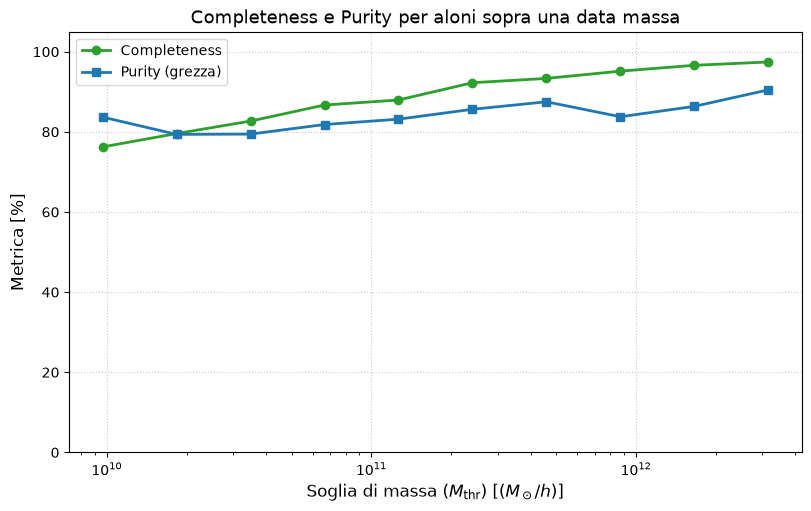

In [15]:
# ============================================================
# 6.2 — COMPLETENESS E PURITY IN FUNZIONE DELLA MASSA (M_thr)
# ============================================================
mass_thresholds = np.logspace(np.log10(MASS_CUT), np.log10(10**12.5), 10)
C_vals, P_vals = [], []

for m_thr in mass_thresholds:
    # Filtriamo FoF e predizioni
    fof_mask = fof["mass"] >= m_thr
    pred_mask = res_base["pred"]["mass"] >= m_thr
    
    fof_thr = {k: v[fof_mask] for k, v in fof.items()}
    pred_thr = {k: v[pred_mask] for k, v in res_base["pred"].items()}
    
    if len(fof_thr["mass"]) == 0 or len(pred_thr["mass"]) == 0:
        C_vals.append(np.nan); P_vals.append(np.nan)
        continue
        
    # Matching per questa soglia
    pairs_thr, pm_thr, fm_thr = match_catalogs(pred_thr, fof_thr, LBOX, DZ)
    
    C_vals.append(fm_thr.sum() / len(fof_thr["mass"]))
    P_vals.append(pm_thr.sum() / len(pred_thr["mass"]))

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.plot(mass_thresholds, np.array(C_vals)*100, "o-", color="tab:green", lw=2, label="Completeness")
ax.plot(mass_thresholds, np.array(P_vals)*100, "s-", color="tab:blue", lw=2, label="Purity (grezza)")

ax.set_xscale("log")
ax.set_xlabel(r"Soglia di massa $\left(M_{\text{thr}}\right)$ [$\left(M_\odot/h\right)$]", fontsize=12)
ax.set_ylabel("Metrica [%]", fontsize=12)
ax.set_title("Completeness e Purity per aloni sopra una data massa", fontsize=13)
ax.set_ylim(0, 105)
ax.grid(True, which="major", ls=":", color="0.8")
ax.legend(frameon=True)
plt.show()

## 7. Robustness Check: il Background Proiettato

Un'ipotesi da testare: la U-Net lavora su mappe 2D proiettate lungo $z$. In ogni pixel c'è sempre un po' di materia diffusa (il "fondo proiettato"). Se questo fondo contribuisse in modo costante alla massa di ogni alone, gli aloni piccoli ne uscirebbero gonfiati in proporzione molto più dei massicci, causando un bias artificiale nel fit di massa ($a < 1$).

**Test controllato:**
1. Stimiamo il fondo per ogni fetta, prendendo la densità mediana nei pixel "quieti" (dove la probabilità della U-Net è $< 1\%$).
2. Ricalcoliamo le masse degli oggetti sottraendo questo fondo:
   $$
   \rho \;\longrightarrow\; \max(\rho - \text{bkg},\, 0)
   $$
3. Rifacciamo il fit di massa.

Se la pendenza $a$ non cambia ($\Delta a \simeq 0$), il fondo è **assolto**.

In [16]:
# ============================================================
# 7.1 — STIMA DEL BACKGROUND E RICALCOLO MASSE
# ============================================================
P_BKG = 0.01

def subtract_background(raw, probs, p_bkg=P_BKG):
    NS_local = raw.shape[0]
    bkg = np.zeros(NS_local)
    for s in range(NS_local):
        sel = probs[s] < p_bkg
        if sel.sum() < 0.001 * sel.size:
            sel = probs[s] < np.percentile(probs[s], 50)
        bkg[s] = np.median(raw[s][sel])
    return np.clip(raw - bkg[:, None, None], 0, None).astype(np.float32), bkg

raw_clean, bkg = subtract_background(raw, probs)

B_clean    = extract_blobs(probs, raw_clean, mpu, LBOX, t=T_BASE, min_area=MIN_AREA_2D_PX)
comp_clean = link_blobs(B_clean, LBOX, n_neighbors=LINK_NEIGHBORS)
pred_clean = build_catalog(B_clean, comp_clean, LBOX, DZ, min_area_3d=AREA_BASE)
pairs_clean, pm_clean, fm_clean = match_catalogs(pred_clean, fof, LBOX, DZ)
ms_clean = mass_stats(pairs_clean, pred_clean, fof)

# Verifica detection identica (usa cache, niente seconda extract_blobs)
same_det = (len(B_clean["x"]) == len(get_blobs(T_BASE)["x"]))
print(f"Detection: {len(B_clean['x']):,} blob | {len(pred_clean['mass']):,} oggetti "
      f"-> {'IDENTICA' if same_det else 'DIVERSA'} alla baseline")

print(f"\n{'':<15} {'PRIMA (raw)':>12} {'DOPO (clean)':>13}")
print("-" * 44)
print(f"{'pendenza a':<15} {ms_base['a']:>12.3f} {ms_clean['a']:>13.3f}")
print(f"{'sigma_MAD':<15} {ms_base['sigma_mad']:>12.3f} {ms_clean['sigma_mad']:>13.3f}")

delta_a = ms_clean["a"] - ms_base["a"]
verdict = ("FONDO ASSOLTO: non è la causa di bias"
           if abs(delta_a) < 0.01 else "effetto non trascurabile: indagare")
print(f"\nDelta a = {delta_a:+.4f} -> {verdict}")

Detection: 7,521 blob | 5,962 oggetti -> IDENTICA alla baseline

                 PRIMA (raw)  DOPO (clean)
--------------------------------------------
pendenza a             0.884         0.882
sigma_MAD              0.133         0.133

Delta a = -0.0018 -> FONDO ASSOLTO: non è la causa di bias


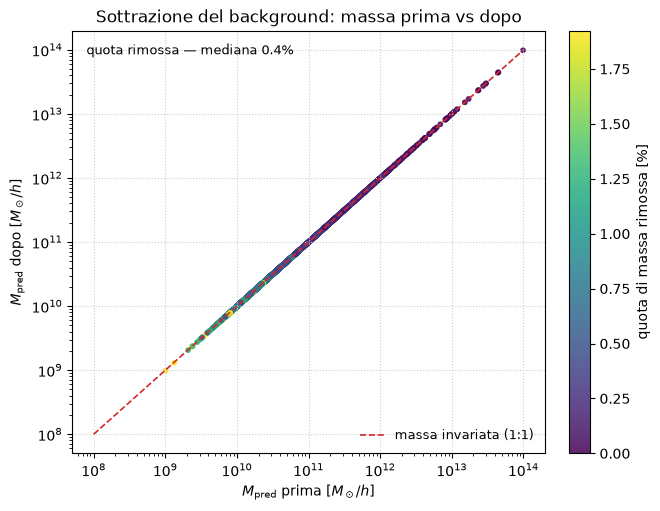

In [17]:
# ============================================================
# 7.2 — CONFRONTO MASSA: PRIMA vs DOPO
# ============================================================
m0 = res_base["pred"]["mass"][res_base["pairs"][:, 0]]
m1 = pred_clean["mass"][res_base["pairs"][:, 0]]
q  = 1.0 - m1 / m0 # Quota di massa rimossa

fig, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

mlo = 10 ** np.floor(np.log10(min(m0.min(), m1.min())))
mhi = 10 ** np.ceil (np.log10(max(m0.max(), m1.max())))
ax.plot([mlo, mhi], [mlo, mhi], color="tab:red", ls="--", lw=1.2, label="massa invariata (1:1)")

sc = ax.scatter(m0, m1, c=q*100, s=10, cmap="viridis", alpha=0.85, vmin=0, vmax=np.percentile(q, 99) * 100)
cb = fig.colorbar(sc, ax=ax)
cb.set_label("quota di massa rimossa [%]")

ax.set(xscale="log", yscale="log", xlabel=r"$M_{\rm pred}$ prima [$M_\odot/h$]", ylabel=r"$M_{\rm pred}$ dopo [$M_\odot/h$]",
       title="Sottrazione del background: massa prima vs dopo")
ax.text(0.03, 0.97, f"quota rimossa — mediana {100*np.median(q):.1f}%", transform=ax.transAxes, va="top", fontsize=9)
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(True, which="major", ls=":", color="0.8")
plt.show()

## 8. Riepilogo Finale

Raccogliamo i numeri chiave emersi dal notebook per la scrittura del capitolo Risultati della tesi. 

I tre pilastri sono:
1.  **Ottima Purezza Fisica**: la U-Net non inventa rumore, ma scopre aloni sotto-cut e substructure.
2.  **Completeness limitata dalla fisica**: il tetto massimo raggiungibile (ceiling) dipende dalla capacità della rete di vedere gli aloni più piccoli.
3.  **Bias di massa compreso**: il fit è compresso per colpa del taglio del catalogo, non per un difetto della rete o della proiezione (background assolto).

In [18]:
# ============================================================
# 9.1 — TABELLA RIASSUNTIVA
# ============================================================
summary = pd.DataFrame([
    # --- Cataloghi ---
    ("FoF (Group) sopra MASS_CUT",        f"{len(fof['mass']):,}",       "§1"),
    ("FoF (Group) totali senza cut",      f"{len(fof_full['mass']):,}",  "§1"),
    ("Subhalo totali",                    f"{len(sub_full['mass']):,}",  "§1"),

    # --- Baseline (t=0.95, area=4) ---
    ("Oggetti 3D predetti",               f"{res_base['n_pred']:,}",     "§3.1"),
    ("Coppie pred <-> FoF",               f"{res_base['n_match']:,}",    "§3.1"),
    ("Completeness C",                    f"{res_base['C']:.3f}",        "§3.1"),
    ("Purity grezza",                     f"{res_base['P_raw']:.4f}",    "§3.1"),
    ("Purity fisica",                     f"{res_base['P_phys']:.4f}",   "§3.1"),
    
    # --- Diagnosi FP ---
    ("  sotto MASS_CUT (reali)",          f"{res_base['n_below']}",      "§4.1"),
    ("  subhalo (reali)",                 f"{res_base['n_sub']}",        "§4.1"),
    ("  doppie detection",                f"{res_base['n_double']}",     "§4.1"),
    ("  rumore vero",                     f"{res_base['n_noise']}",      "§4.1"),

    # --- Massa e Bias ---
    ("Fit massa pendenza a (globale)",    f"{ms_base['a']:.3f}",         "§3.2"),
    ("Fit massa sigma_MAD (globale)",     f"{ms_base['sigma_mad']:.3f}", "§3.2"),
    ("Delta a dopo sottr. background",    f"{delta_a:+.4f}",             "§7.1"),
    ("Massa rimossa (mediana)",           f"{100*np.median(q):.1f}%",    "§7.2"),
    
    # --- Completeness ceiling ---
    ("Completeness attuale",              f"{100*comp_now:.1f}%",        "§3.3"),
    ("Completeness ceiling",              f"{100*comp_ceiling:.1f}%",    "§3.3"),
    ("Margine algoritmo [pp]",            f"{100*(comp_ceiling-comp_now):.1f}", "§3.3"),

    # --- Robustness ---
    ("Delta a dopo sottr. background",    f"{delta_a:+.4f}",             "§8.1"),
    ("Massa rimossa (mediana)",           f"{100*np.median(q):.1f}%",    "§8.2"),
], columns=["Quantità", "Valore", "Sezione"])

print(summary.to_string(index=False))

                      Quantità  Valore Sezione
    FoF (Group) sopra MASS_CUT   4,701      §1
  FoF (Group) totali senza cut  12,304      §1
                Subhalo totali  16,223      §1
           Oggetti 3D predetti   5,962    §3.1
           Coppie pred <-> FoF   3,846    §3.1
                Completeness C   0.818    §3.1
                 Purity grezza  0.6451    §3.1
                 Purity fisica  0.9968    §3.1
        sotto MASS_CUT (reali)    2084    §4.1
               subhalo (reali)      13    §4.1
              doppie detection       7    §4.1
                   rumore vero      12    §4.1
Fit massa pendenza a (globale)   0.884    §3.2
 Fit massa sigma_MAD (globale)   0.133    §3.2
Delta a dopo sottr. background -0.0018    §7.1
       Massa rimossa (mediana)    0.4%    §7.2
          Completeness attuale   81.8%    §3.3
          Completeness ceiling   99.4%    §3.3
        Margine algoritmo [pp]    17.6    §3.3
Delta a dopo sottr. background -0.0018    §8.1
       Massa 

In [19]:
with open(os.path.join(RUN_DIR, "chosen_threshold.json"), "w") as fh:
    json.dump({"t": float(T_FINAL), "area3d": int(AREA_FINAL),
               "note": "scelta dopo griglia 4x3 su LH_105 (val)",
               "metrics": {"C": float(row_final["C"]),
                           "P_phys": float(row_final["P_phys"]),
                           "n_pred": int(row_final["n_pred"]),
                           "n_noise": int(row_final["n_noise"])}}, fh, indent=2)